# Projet de Machine Learning 

### Sujet 1

**Contexte** :  Ce projet vise à mettre en place un système de maintenance prédictive pour les machines de l'usine et à analyser les causes qui font que la condition de la valve d'un cycle de production est non optimale parfois. 

**Objectif** : Construisez un modèle ML pour prédire si la condition valve est optimale (=100%) ou non, pour chaque cycle. Vous utiliserez les 2000 premiers cycles pour construire le modèle et le reste comme échantillon de test final.   

**Données** : Les données sont disponibles dans un Drive. Les données sont décrites à utiliser uniquement les 3 fichiers suivants, chaque ligne représentant un cycle :  
- PS2 (Pression (bar) échantillonnage 100Hz)  
- FS1 (Volume flow (l/min) échantillonnage 10Hz)  
- Profile : Fichier avec les variables dont la "valve condition" qui nous intéresse. 

## 1. Prétraitement des données.

### 1.1. Chargement des données et statistiques descriptives.

In [1]:
# Chargement des données et statistiques descriptives
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
import warnings
warnings.filterwarnings('ignore', message='invalid value encountered in divide', category=RuntimeWarning)

N_DEV = 2000          # 2000 premiers cycles : construction du modèle
RANDOM_STATE = 0

# Une ligne = un cycle. Fichiers sans en-tête, colonnes séparées par des tabulations.
ps2 = pd.read_csv('data/PS2.txt', sep=r'\s+', header=None)
fs1 = pd.read_csv('data/FS1.txt', sep=r'\s+', header=None)
profile = pd.read_csv('data/profile.txt', sep=r'\s+', header=None, names=['Cooler', 'Valve', 'Pump_leakage', 'Accumulator', 'Stable_flag'])

print('PS2     :', ps2.shape, '(cycles x mesures à 100 Hz)')
print('FS1     :', fs1.shape, '(cycles x mesures à 10 Hz)')
print('profile :', profile.shape)

assert len(ps2) == len(fs1) == len(profile), 'Nombre de cycles incohérent entre les fichiers'

PS2     : (2205, 6000) (cycles x mesures à 100 Hz)
FS1     : (2205, 600) (cycles x mesures à 10 Hz)
profile : (2205, 5)


In [2]:
# Séparation : 2000 premiers cycles (développement) / cycles restants (test final)
ps2_dev, ps2_test = ps2.iloc[:N_DEV], ps2.iloc[N_DEV:]
fs1_dev, fs1_test = fs1.iloc[:N_DEV], fs1.iloc[N_DEV:]
profile_dev, profile_test = profile.iloc[:N_DEV], profile.iloc[N_DEV:]

print('Cycles de développement :', len(profile_dev))
print('Cycles de test final    :', len(profile_test))

Cycles de développement : 2000
Cycles de test final    : 205


In [3]:
# 1.1 Statistiques descriptives de profile.txt (développement)
print(profile_dev.describe().round(2))

        Cooler    Valve  Pump_leakage  Accumulator  Stable_flag
count  2000.00  2000.00       2000.00      2000.00      2000.00
mean     35.22    90.95          0.67       108.65         0.37
std      39.88    10.67          0.82        16.53         0.48
min       3.00    73.00          0.00        90.00         0.00
25%       3.00    80.00          0.00        90.00         0.00
50%      20.00   100.00          0.00       100.00         0.00
75%     100.00   100.00          1.00       130.00         1.00
max     100.00   100.00          2.00       130.00         1.00


In [4]:
# Statistiques descriptives des signaux bruts (toutes les mesures, développement)
for nom, df in [('PS2 (bar)', ps2_dev), ('FS1 (l/min)', fs1_dev)]:
    v = df.to_numpy().ravel()
    print(f'{nom:12s} min={v.min():8.2f} | moyenne={v.mean():8.2f} | médiane={np.median(v):8.2f} | '
          f'max={v.max():8.2f} | écart-type={v.std():7.2f}')

PS2 (bar)    min=    0.00 | moyenne=  109.39 | médiane=  125.66 | max=  167.74 | écart-type=  48.18
FS1 (l/min)  min=    0.00 | moyenne=    6.16 | médiane=    7.64 | max=   20.48 | écart-type=   3.23


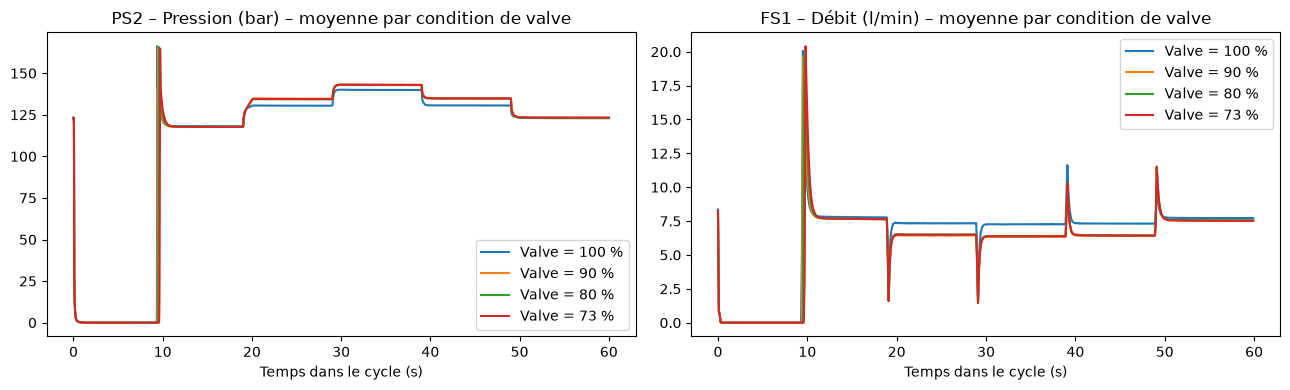

In [5]:
# Allure moyenne d'un cycle selon la condition de la valve
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nom, df, hz) in zip(axes, [('PS2 – Pression (bar)', ps2_dev, 100), ('FS1 – Débit (l/min)', fs1_dev, 10)]):
    t = np.arange(df.shape[1]) / hz
    for val in sorted(profile_dev['Valve'].unique(), reverse=True):
        masque = (profile_dev['Valve'] == val).to_numpy()
        ax.plot(t, df[masque].mean(axis=0), label=f'Valve = {val} %')
    ax.set_title(nom + ' – moyenne par condition de valve')
    ax.set_xlabel('Temps dans le cycle (s)')
    ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# Résumé de chaque cycle par des statistiques descriptives (une ligne = un cycle)
def extraire_features(df, prefixe):
    X = df.to_numpy(dtype=float)
    f = pd.DataFrame(index=df.index)
    f[f'{prefixe}_mean'] = X.mean(axis=1)
    f[f'{prefixe}_std'] = X.std(axis=1)
    f[f'{prefixe}_min'] = X.min(axis=1)
    f[f'{prefixe}_max'] = X.max(axis=1)
    f[f'{prefixe}_median'] = np.median(X, axis=1)
    f[f'{prefixe}_q25'] = np.percentile(X, 25, axis=1)
    f[f'{prefixe}_q75'] = np.percentile(X, 75, axis=1)
    f[f'{prefixe}_skew'] = stats.skew(X, axis=1)
    f[f'{prefixe}_kurtosis'] = stats.kurtosis(X, axis=1)
    return f

# Calcul cycle par cycle : aucune information du test n'est utilisée pour le développement
features = pd.concat([extraire_features(ps2, 'PS2'), extraire_features(fs1, 'FS1')], axis=1)
X_dev, X_test = features.iloc[:N_DEV], features.iloc[N_DEV:]

print('Tableau de variables :', features.shape, '(cycles x variables)')
X_dev.describe().T.round(3)

Tableau de variables : (2205, 18) (cycles x variables)


,count,mean,std,min,25%,50%,75%,max
PS2_mean,2000.0,109.393,5.235,104.406,106.835,107.558,109.380,131.589
PS2_std,2000.0,47.775,3.432,45.203,46.153,46.639,47.158,59.548
PS2_min,2000.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
PS2_max,2000.0,166.450,0.998,155.040,166.100,166.570,167.020,167.740
PS2_median,2000.0,128.554,3.619,124.445,127.025,127.810,129.875,165.400
PS2_q25,2000.0,117.997,1.715,112.840,116.480,117.930,120.060,120.690
PS2_q75,2000.0,132.728,12.020,125.040,127.645,128.300,130.470,165.560
PS2_skew,2000.0,-1.771,0.146,-1.842,-1.835,-1.830,-1.794,-1.318
PS2_kurtosis,2000.0,1.351,0.305,0.455,1.340,1.477,1.506,1.522
FS1_mean,2000.0,6.161,1.077,2.019,6.376,6.577,6.647,6.723


### 1.2. Gestion des valeurs manquantes et détection des valeurs aberrantes.

In [7]:
# Valeurs manquantes : comptage
print('Valeurs manquantes PS2      :', int(ps2.isnull().sum().sum()))
print('Valeurs manquantes FS1      :', int(fs1.isnull().sum().sum()))
print('Valeurs manquantes profile  :', int(profile.isnull().sum().sum()))
print('Valeurs manquantes variables :', int(features.isnull().sum().sum()))

Valeurs manquantes PS2      : 0
Valeurs manquantes FS1      : 0
Valeurs manquantes profile  : 0
Valeurs manquantes variables : 0


In [8]:
# Gestion : médiane du développement, uniquement s'il manque des valeurs
if features.isnull().any().any():
    medianes = X_dev.median()
    X_dev, X_test = X_dev.fillna(medianes), X_test.fillna(medianes)
    print('-> Valeurs manquantes remplacées par la médiane du développement.')
else:
    print('-> Aucune valeur manquante : aucun traitement nécessaire.')

-> Aucune valeur manquante : aucun traitement nécessaire.


In [9]:
# Valeurs aberrantes : règle de l'IQR, bornes calculées sur le développement
Q1, Q3 = X_dev.quantile(0.25), X_dev.quantile(0.75)
IQR = Q3 - Q1
aberrant = (X_dev < Q1 - 1.5 * IQR) | (X_dev > Q3 + 1.5 * IQR)

taux = (aberrant.mean() * 100).sort_values(ascending=False)
print('Variables avec le plus de valeurs aberrantes (% des cycles) :')
print(taux.head(8).round(1))
print(f"\nCycles ayant au moins une variable aberrante : {aberrant.any(axis=1).mean() * 100:.1f} %")
print('\nPart de cycles avec >= 1 valeur aberrante, selon la condition de la valve (%) :')
print((aberrant.any(axis=1).groupby(profile_dev['Valve']).mean() * 100).round(1))

Variables avec le plus de valeurs aberrantes (% des cycles) :
FS1_std         13.2
PS2_mean        12.0
PS2_std         12.0
FS1_mean        12.0
PS2_skew        12.0
PS2_kurtosis    12.0
FS1_q25         12.0
FS1_skew        12.0
dtype: float64

Cycles ayant au moins une variable aberrante : 19.7 %

Part de cycles avec >= 1 valeur aberrante, selon la condition de la valve (%) :
Valve
73     23.4
80     23.3
90     26.1
100    15.5
dtype: float64


### 1.3. Encodage des variables catégorielles.

In [10]:
# Encodage des variables catégorielles : y en a-t-il ?
print('Types des variables explicatives :')
print(X_dev.dtypes.value_counts())
print('\nValeurs possibles de la condition de la valve :', sorted(int(v) for v in profile_dev['Valve'].unique()))

Types des variables explicatives :
float64    18
Name: count, dtype: int64

Valeurs possibles de la condition de la valve : [73, 80, 90, 100]


### 1.4. Transformation du problème en classification binaire.

In [11]:
# Cible binaire : 1 = valve optimale (100 %), 0 = non optimale (90, 80 ou 73 %)
y_all = (profile['Valve'] == 100).astype(int)
y_dev, y_test = y_all.iloc[:N_DEV], y_all.iloc[N_DEV:]

print(pd.crosstab(profile_dev['Valve'], y_dev, rownames=['Valve (%)'], colnames=['Cible binaire']))

Cible binaire    0     1
Valve (%)               
73             320     0
80             318     0
90             310     0
100              0  1052


### 1.5. Analyse de la distribution des classes.

                  Effectif  Proportion
0 – non optimale       948       0.474
1 – optimale          1052       0.526


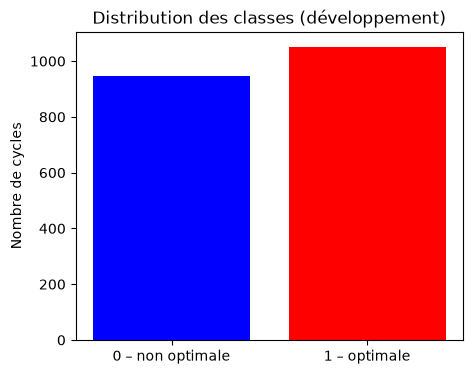

In [12]:
# Équilibre des classes (développement)
comptes = y_dev.value_counts().sort_index()
parts = y_dev.value_counts(normalize=True).sort_index()
print(pd.DataFrame({'Effectif': comptes.values, 'Proportion': parts.round(3).values},
                   index=['0 – non optimale', '1 – optimale']))

plt.figure(figsize=(5, 4))
plt.bar(['0 – non optimale', '1 – optimale'], comptes.values, color=['blue', 'red'])
plt.ylabel('Nombre de cycles')
plt.title('Distribution des classes (développement)')
plt.show()

### 1.6. Analyse des corrélations entre les variables.

In [ ]:
corr = X_dev.corr()
corr_cible = X_dev.apply(lambda col: col.corr(y_dev)).dropna().sort_values(key=abs, ascending=False)

print('Les 10 variables les plus corrélées à la cible (valve optimale) :')
print(corr_cible.head(10).round(3))

paires = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().dropna()
fortes = paires[paires.abs() > 0.95].sort_values(key=abs, ascending=False)
print(f'\nPaires de variables fortement corrélées (|r| > 0.95) : {len(fortes)} sur {len(paires)}')
print(fortes.head(10).round(3))

Les 10 variables les plus corrélées à la cible (valve optimale) :
PS2_kurtosis    0.343
PS2_skew       -0.270
FS1_skew       -0.259
FS1_mean        0.231
PS2_std        -0.225
FS1_q25         0.210
FS1_median      0.207
FS1_q75         0.186
FS1_std        -0.185
PS2_q75        -0.175
dtype: float64

Paires de variables fortement corrélées (|r| > 0.95) : 33 sur 136
PS2_skew    PS2_kurtosis   -0.994
FS1_mean    FS1_skew       -0.994
PS2_std     PS2_q75         0.994
FS1_mean    FS1_q25         0.993
            FS1_median      0.989
PS2_q75     FS1_q25        -0.989
PS2_skew    FS1_q25        -0.989
PS2_mean    PS2_std         0.988
FS1_q25     FS1_skew       -0.987
FS1_median  FS1_q25         0.983
dtype: float64


### 1.7. Visualisations.

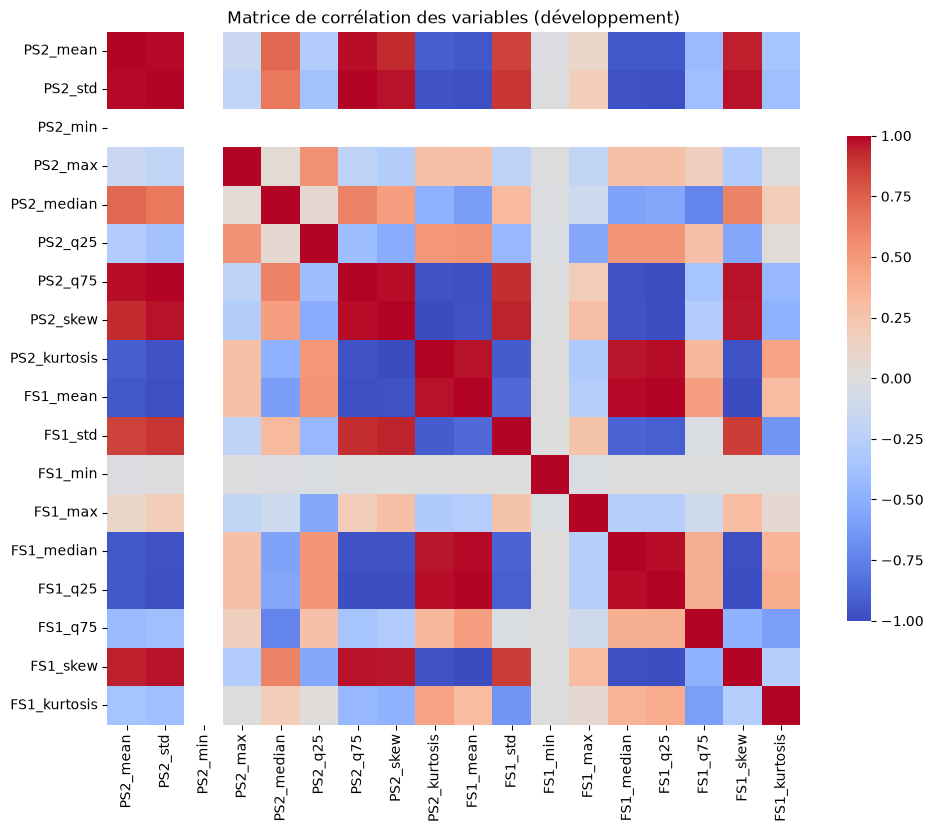

In [ ]:
# Matrice de corrélation
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.7})
plt.title('Matrice de corrélation des variables (développement)')
plt.show()

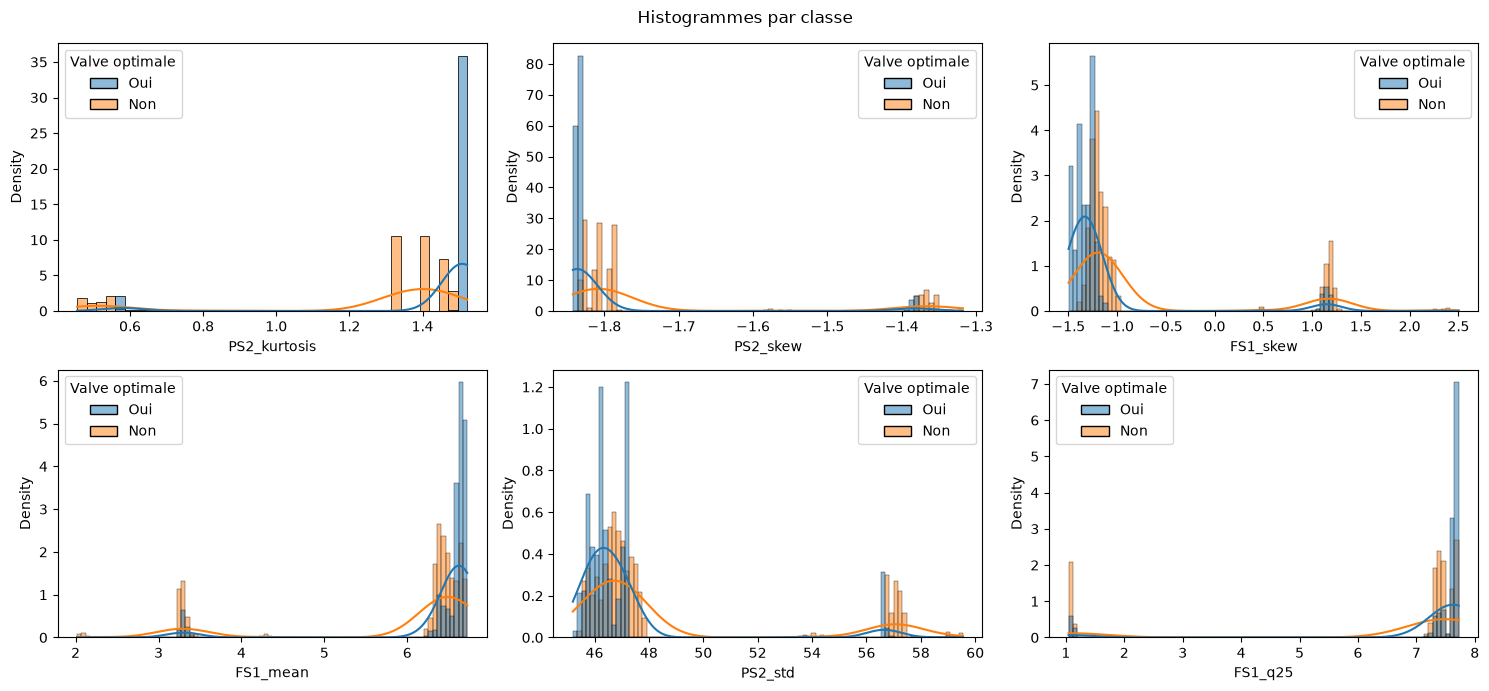

In [ ]:
# Histogrammes des 6 variables les plus corrélées à la cible
top6 = corr_cible.index[:6].tolist()
donnees = X_dev[top6].copy()
donnees['Valve optimale'] = y_dev.map({0: 'Non', 1: 'Oui'})

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.histplot(data=donnees, x=col, hue='Valve optimale', kde=True, stat='density', common_norm=False, ax=ax)
fig.suptitle('Histogrammes par classe')
plt.tight_layout()
plt.show()

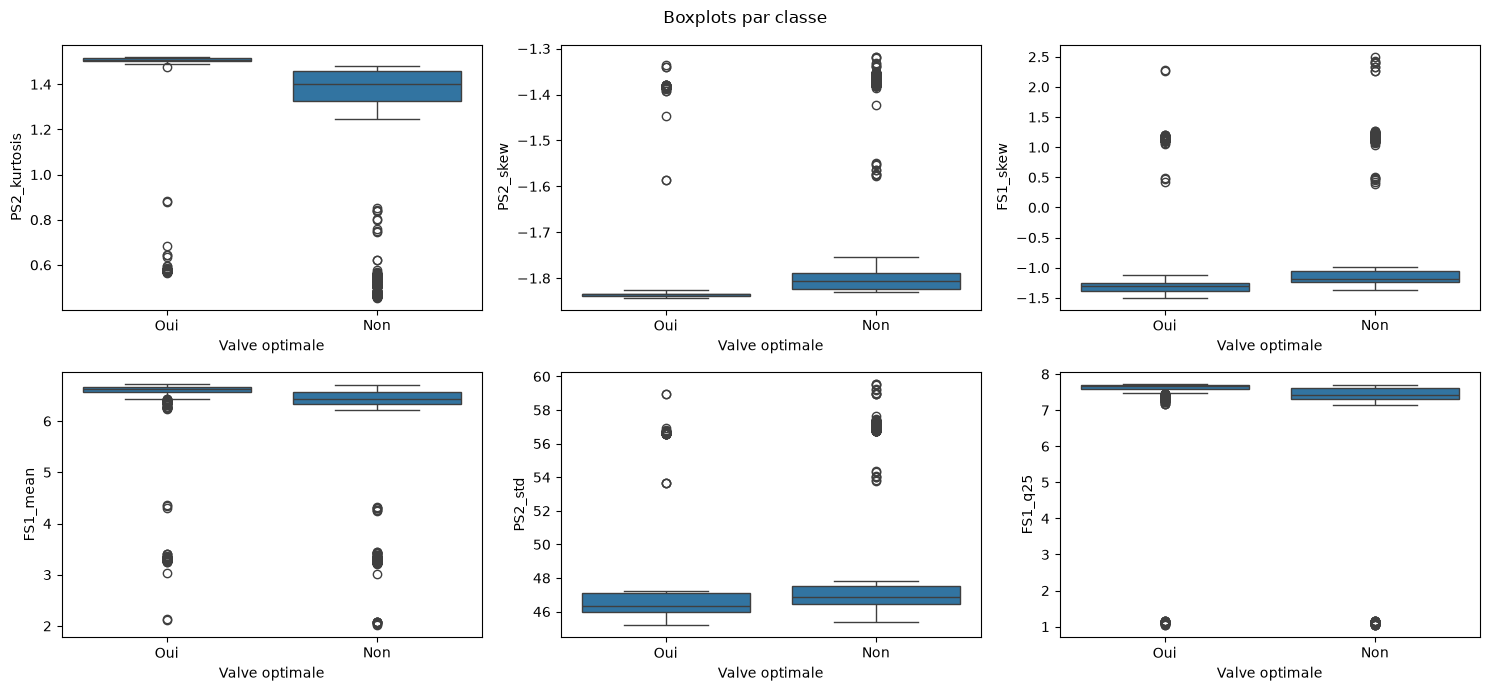

In [16]:
# 1.7 (suite) Boxplots des 6 variables les plus corrélées à la cible
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.boxplot(data=donnees, x='Valve optimale', y=col, ax=ax)
fig.suptitle('Boxplots par classe')
plt.tight_layout()
plt.show()

### 1.8 Utilisation de méthodes de sélection de variables (Features selection).

In [ ]:
# Sélection de variables : filtre de colinéarité, puis trois critères de pertinence
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

SEUIL_CORR = 0.95
K_FEATURES = 8

# Variables constantes écartées, puis filtre de colinéarité : parmi des variables corrélées à plus de 0,95, on garde la plus liée à la cible
constantes = [c for c in X_dev.columns if X_dev[c].nunique() <= 2]      # variables constantes ou quasi constantes
gardees = []
for feat in corr_cible.index:
    if feat in constantes:
        continue
    if all(abs(corr.loc[feat, g]) <= SEUIL_CORR for g in gardees):
        gardees.append(feat)
print(f'Variables de départ : {X_dev.shape[1]} | constantes : {constantes} | après filtre de colinéarité : {len(gardees)}')

Variables de départ : 18 | constantes : ['PS2_min', 'FS1_min'] | après filtre de colinéarité : 9


In [ ]:
# Scores de pertinence : ANOVA (F), information mutuelle, importance d'une forêt aléatoire
Xs = X_dev[gardees]
f_scores, _ = f_classif(Xs, y_dev)
mi_scores = mutual_info_classif(Xs, y_dev, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(Xs, y_dev)

scores = pd.DataFrame({'ANOVA_F': f_scores, 'Info_mutuelle': mi_scores,
                       'RF_importance': rf.feature_importances_}, index=gardees)

# Agrégation par rang moyen (rang 1 = meilleure variable)
scores['Rang_moyen'] = scores.rank(ascending=False).mean(axis=1)
scores = scores.sort_values('Rang_moyen')
print(scores.round(4))

               ANOVA_F  Info_mutuelle  RF_importance  Rang_moyen
PS2_kurtosis  266.3891         0.6786         0.6599      1.0000
FS1_q75        71.3112         0.2319         0.1174      2.3333
FS1_std        70.6805         0.1802         0.0846      3.6667
PS2_mean       37.3843         0.3187         0.0595      3.6667
PS2_q25        26.5242         0.1976         0.0248      5.0000
PS2_median     14.5911         0.1795         0.0165      6.6667
FS1_max        45.0421         0.0310         0.0083      7.0000
FS1_kurtosis    1.2227         0.0877         0.0229      7.3333
PS2_max        11.6034         0.0680         0.0061      8.3333


8 variables retenues :
['PS2_kurtosis', 'FS1_q75', 'FS1_std', 'PS2_mean', 'PS2_q25', 'PS2_median', 'FS1_max', 'FS1_kurtosis']


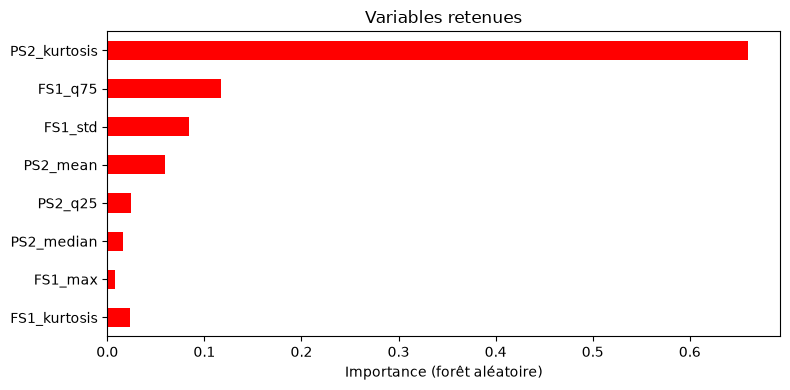

In [60]:
# Variables retenues et jeux de données prêts pour l'étape 2
selected_features = scores.index[:K_FEATURES].tolist()
print(f'{len(selected_features)} variables retenues :')
print(selected_features)

plt.figure(figsize=(8, 4))
scores.loc[selected_features, 'RF_importance'][::-1].plot.barh(color='red')
plt.xlabel('Importance (forêt aléatoire)')
plt.title('Variables retenues')
plt.tight_layout()
plt.show()

# Mêmes colonnes pour le test final (aucune statistique du test n'est utilisée)
X_dev_sel, X_test_sel = X_dev[selected_features], X_test[selected_features]

## 2. Modélisation et évaluation.

### 2.1. Préparation des données.

In [20]:
# 2.1 Régression logistique – préparation : jeux d'entraînement / validation (découpage par blocs de conditions)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Des cycles consécutifs ont les mêmes conditions (refroidisseur, fuite de pompe, accumulateur) : ils sont quasi identiques.
# On forme donc des blocs avec ces trois colonnes, qui servent UNIQUEMENT à découper, jamais comme variables explicatives.
groupes = profile_dev[['Cooler', 'Pump_leakage', 'Accumulator']].astype(str).agg('-'.join, axis=1).to_numpy()

# 5 plis stratifiés qui gardent chaque bloc entier du même côté ; le 1er pli sert de validation (environ 20 %)
cv_blocs = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plis = list(cv_blocs.split(X_dev_sel, y_dev, groupes))
idx_tr, idx_val = plis[0]
X_tr, X_val = X_dev_sel.iloc[idx_tr], X_dev_sel.iloc[idx_val]
y_tr, y_val = y_dev.iloc[idx_tr], y_dev.iloc[idx_val]

assert not set(groupes[idx_tr]) & set(groupes[idx_val]), 'Un bloc ne doit pas être des deux côtés'
print('Entraînement :', X_tr.shape, '| Validation :', X_val.shape)
print('Part de valves optimales : entraînement = %.3f | validation = %.3f' % (y_tr.mean(), y_val.mean()))

modeles = {}      # modèles entraînés

def entrainer(nom, modele):
    """Entraîne le modèle sur l'entraînement et affiche l'accuracy d'entraînement et de validation."""
    modele.fit(X_tr, y_tr)
    modeles[nom] = modele
    print(f'{nom:28s} accuracy entraînement = {modele.score(X_tr, y_tr):.3f} | validation = {modele.score(X_val, y_val):.3f}')
    return modele

Entraînement : (1544, 8) | Validation : (456, 8)
Part de valves optimales : entraînement = 0.503 | validation = 0.605


2.2. Régression logistique.

In [ ]:
from sklearn.linear_model import LogisticRegression

entrainer('Régression logistique',
          make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)))

Régression logistique        accuracy entraînement = 0.960 | validation = 0.846


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['PS2_kurtosis','FS1_q75','FS1_std',...,'PS2_median','FS1_max', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [ ]:
# Coefficients du modèle (variables standardisées : comparables entre eux)
coef = pd.Series(modeles['Régression logistique'][-1].coef_[0], index=X_tr.columns).sort_values(key=abs, ascending=False)
print(coef.round(3))
print('Intercept :', round(float(modeles['Régression logistique'][-1].intercept_[0]), 3))

PS2_kurtosis    10.225
PS2_mean         8.705
PS2_q25         -2.891
FS1_kurtosis    -2.521
FS1_std         -1.167
FS1_max          0.948
PS2_median      -0.685
FS1_q75         -0.022
dtype: float64
Intercept : -0.513


### 2.3 k-NN.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

entrainer('k-NN (k=5)', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)))

k-NN (k=5)                   accuracy entraînement = 0.986 | validation = 0.739


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['PS2_kurtosis','FS1_q75','FS1_std',...,'PS2_median','FS1_max', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### 2.4. Arbre de décision

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

entrainer('Arbre de décision', DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=RANDOM_STATE))

Arbre de décision            accuracy entraînement = 1.000 | validation = 0.993


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

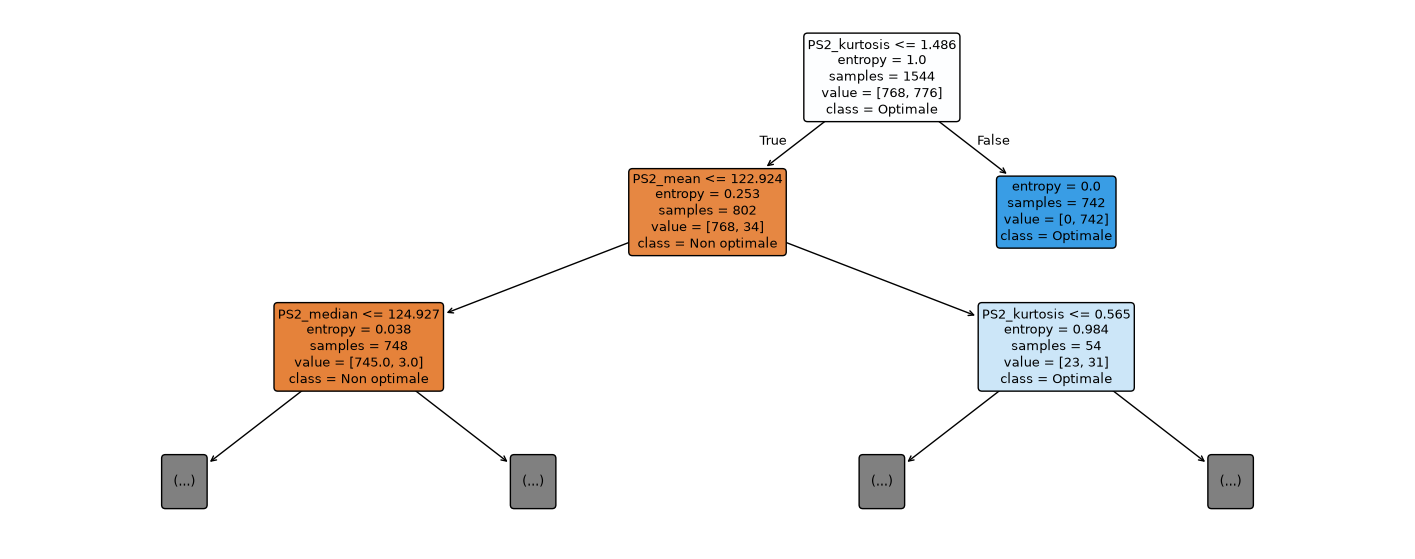

In [ ]:
plt.figure(figsize=(18, 7))
plot_tree(modeles['Arbre de décision'], max_depth=2, feature_names=list(X_tr.columns),
          class_names=['Non optimale', 'Optimale'], filled=True, rounded=True, fontsize=9)
plt.show()

### 2.5. Naive Bayes.

In [ ]:
from sklearn.naive_bayes import GaussianNB

entrainer('Naive Bayes', make_pipeline(StandardScaler(), GaussianNB()))

Naive Bayes                  accuracy entraînement = 0.562 | validation = 0.351


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('gaussiannb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['PS2_kurtosis','FS1_q75','FS1_std',...,'PS2_median','FS1_max', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### 2.6. SVM.

In [27]:
# 2.5 SVM linéaire et SVM à noyau gaussien (RBF), variables standardisées
from sklearn.svm import SVC

entrainer('SVM linéaire', make_pipeline(StandardScaler(), SVC(kernel='linear', random_state=RANDOM_STATE)))
entrainer('SVM RBF', make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=RANDOM_STATE)))

SVM linéaire                 accuracy entraînement = 0.994 | validation = 0.987
SVM RBF                      accuracy entraînement = 0.970 | validation = 0.928


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['PS2_kurtosis','FS1_q75','FS1_std',...,'PS2_median','FS1_max', 'FS1_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### 2.7. Ensemble learning.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

entrainer('Forêt aléatoire', RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1))
entrainer('Gradient Boosting', GradientBoostingClassifier(random_state=RANDOM_STATE))

Forêt aléatoire              accuracy entraînement = 1.000 | validation = 0.996
Gradient Boosting            accuracy entraînement = 1.000 | validation = 0.993


,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (imp

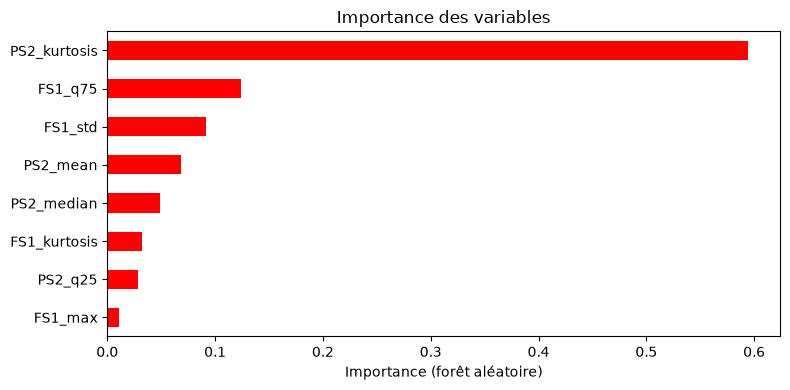

In [61]:
imp = pd.Series(modeles['Forêt aléatoire'].feature_importances_, index=X_tr.columns).sort_values()

plt.figure(figsize=(8, 4))
imp.plot.barh(color='red')
plt.xlabel('Importance (forêt aléatoire)')
plt.title('Importance des variables')
plt.tight_layout()
plt.show()

### 2.8. Justification du choix des modèles.

In [ ]:
# Caractéristiques des données qui guident le choix des modèles
n = X_dev_sel.shape[1]
corr_sel = X_dev_sel.corr().abs().where(~np.eye(n, dtype=bool), 0)

resume = pd.DataFrame({'Asymétrie': X_dev_sel.skew(),
                       'Kurtosis': X_dev_sel.kurt(),
                       'Min': X_dev_sel.min(),
                       'Max': X_dev_sel.max(),
                       '|r| max avec une autre variable': corr_sel.max()})
print(resume.round(2))

etendues = X_dev_sel.max() - X_dev_sel.min()
print(f'\nRapport entre la plus grande et la plus petite étendue : {etendues.max() / etendues.min():.1f}')

              Asymétrie  Kurtosis     Min     Max  \
PS2_kurtosis      -2.19      3.16    0.46    1.52   
FS1_q75          -11.17    138.85    1.15    7.95   
FS1_std            2.22      3.61    2.66    3.74   
PS2_mean           2.17      3.53  104.41  131.59   
PS2_q25            0.16     -1.15  112.84  120.69   
PS2_median         6.64     63.71  124.44  165.40   
FS1_max           -1.25      0.42   18.70   20.48   
FS1_kurtosis       3.46     38.19   -0.35    7.66   

              |r| max avec une autre variable  
PS2_kurtosis                             0.92  
FS1_q75                                  0.74  
FS1_std                                  0.92  
PS2_mean                                 0.92  
PS2_q25                                  0.55  
PS2_median                               0.74  
FS1_max                                  0.55  
FS1_kurtosis                             0.65  

Rapport entre la plus grande et la plus petite étendue : 38.4


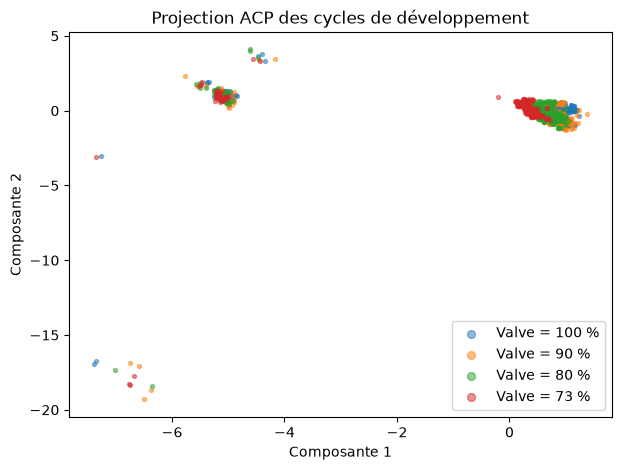

In [ ]:
# La classe « non optimale » regroupe trois états de valve : projection en 2 dimensions (ACP)
from sklearn.decomposition import PCA

Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(StandardScaler().fit_transform(X_dev_sel))

plt.figure(figsize=(7, 5))
for val in sorted(profile_dev['Valve'].unique(), reverse=True):
    m = (profile_dev['Valve'] == val).to_numpy()
    plt.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, label=f'Valve = {val} %')
plt.xlabel('Composante 1')
plt.ylabel('Composante 2')
plt.title('Projection ACP des cycles de développement')
plt.legend(markerscale=2)
plt.show()

## 3. Évaluation des modèles.

### 3.1. Métriques : accuracy, précision, rappel, F1-score.

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

lignes = {}
for nom, m in modeles.items():
    y_pred = m.predict(X_val)
    lignes[nom] = {'Accuracy': accuracy_score(y_val, y_pred),
                   'Précision': precision_score(y_val, y_pred),
                   'Rappel': recall_score(y_val, y_pred),
                   'F1': f1_score(y_val, y_pred)}
metriques = pd.DataFrame(lignes).T
metriques.sort_values('F1', ascending=False).round(3)

,Accuracy,Précision,Rappel,F1
Forêt aléatoire,0.996,1.000,0.993,0.996
Arbre de décision,0.993,0.993,0.996,0.995
Gradient Boosting,0.993,0.993,0.996,0.995
SVM linéaire,0.987,0.982,0.996,0.989
SVM RBF,0.928,1.000,0.880,0.936
Régression logistique,0.846,0.952,0.786,0.861
k-NN (k=5),0.739,0.964,0.591,0.733
Naive Bayes,0.351,0.438,0.257,0.324


### 3.2. Matrice de confusion.

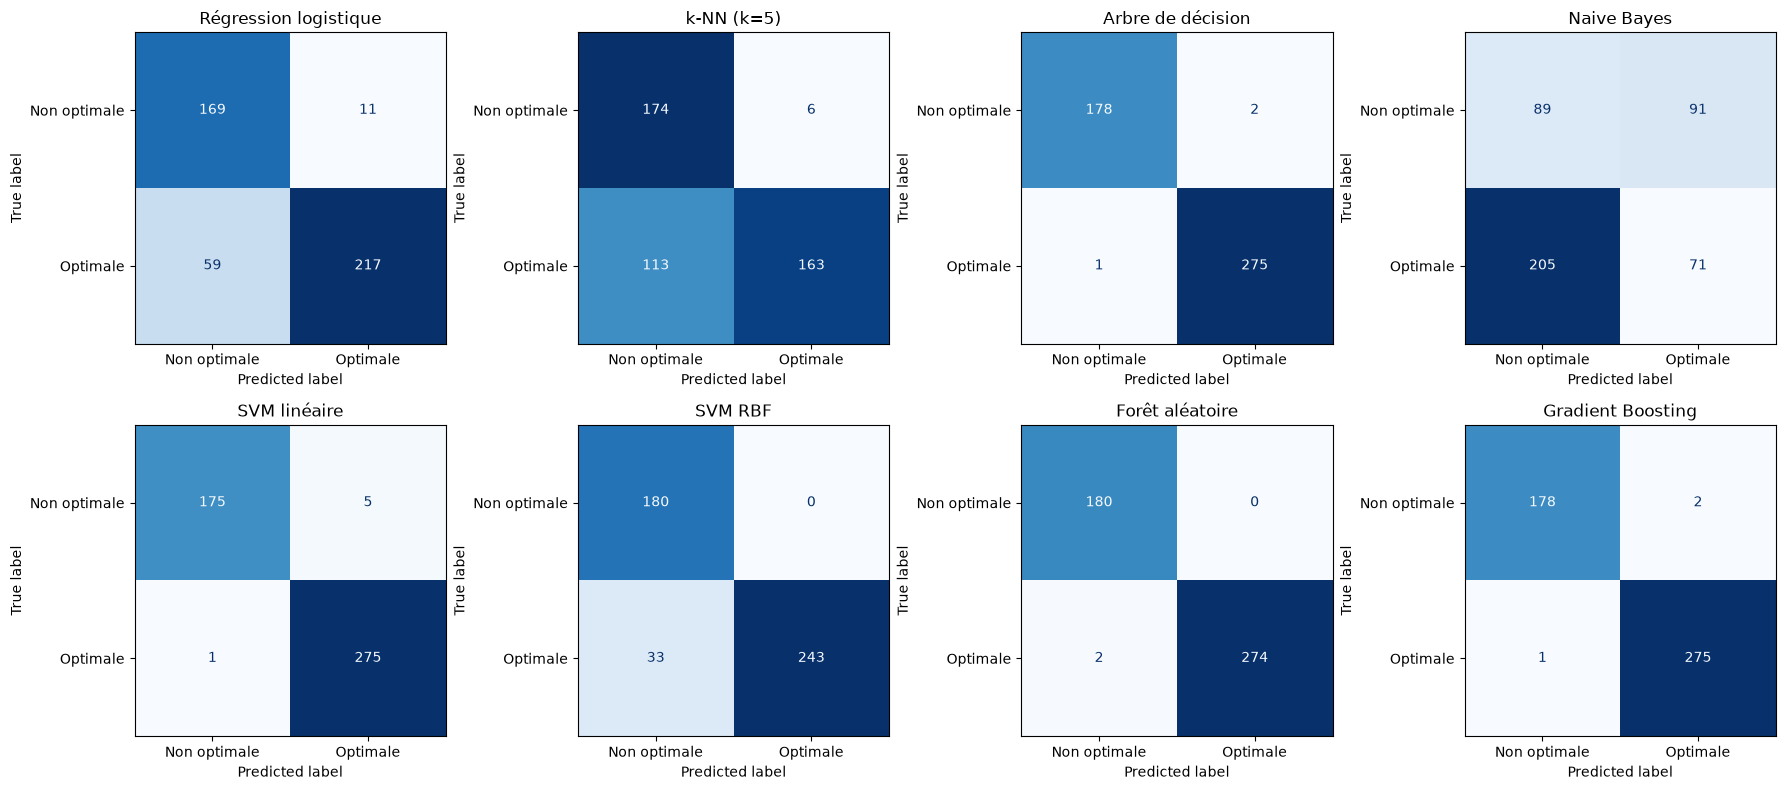

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (nom, m) in zip(axes.ravel(), modeles.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_val, y_val, display_labels=['Non optimale', 'Optimale'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

In [ ]:
# Types d'erreurs de chaque modèle
erreurs = {}
for nom, m in modeles.items():
    tn, fp, fn, tp = confusion_matrix(y_val, m.predict(X_val)).ravel()
    erreurs[nom] = {'Vrais négatifs': tn, 'Faux positifs (non optimale prédite optimale)': fp,
                    'Faux négatifs (optimale prédite non optimale)': fn, 'Vrais positifs': tp}
pd.DataFrame(erreurs).T

,Vrais négatifs,Faux positifs (non optimale prédite optimale),Faux négatifs (optimale prédite non optimale),Vrais positifs
Régression logistique,169,11,59,217
k-NN (k=5),174,6,113,163
Arbre de décision,178,2,1,275
Naive Bayes,89,91,205,71
SVM linéaire,175,5,1,275
SVM RBF,180,0,33,243
Forêt aléatoire,180,0,2,274
Gradient Boosting,178,2,1,275


### 3.3. Courbe ROC et AUC.

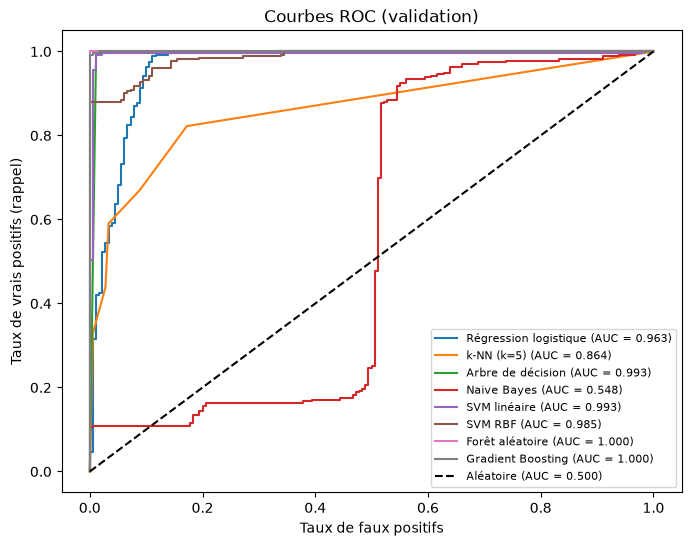

In [ ]:
def scores_modele(modele, X):
    """Probabilité de la classe 1 si disponible, sinon score de décision (SVM)."""
    if hasattr(modele, 'predict_proba'):
        return modele.predict_proba(X)[:, 1]
    return modele.decision_function(X)

plt.figure(figsize=(8, 6))
auc = {}
for nom, m in modeles.items():
    s = scores_modele(m, X_val)
    fpr, tpr, _ = roc_curve(y_val, s)
    auc[nom] = roc_auc_score(y_val, s)
    plt.plot(fpr, tpr, label=f'{nom} (AUC = {auc[nom]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aléatoire (AUC = 0.500)')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs (rappel)')
plt.title('Courbes ROC (validation)')
plt.legend(fontsize=8)
plt.show()

### 3.4. Comparaison des performances et interprétation des résultats.

                       Accuracy  Précision  Rappel     F1    AUC
Forêt aléatoire           0.996      1.000   0.993  0.996  1.000
Arbre de décision         0.993      0.993   0.996  0.995  0.993
Gradient Boosting         0.993      0.993   0.996  0.995  1.000
SVM linéaire              0.987      0.982   0.996  0.989  0.993
SVM RBF                   0.928      1.000   0.880  0.936  0.985
Régression logistique     0.846      0.952   0.786  0.861  0.963
k-NN (k=5)                0.739      0.964   0.591  0.733  0.864
Naive Bayes               0.351      0.438   0.257  0.324  0.548


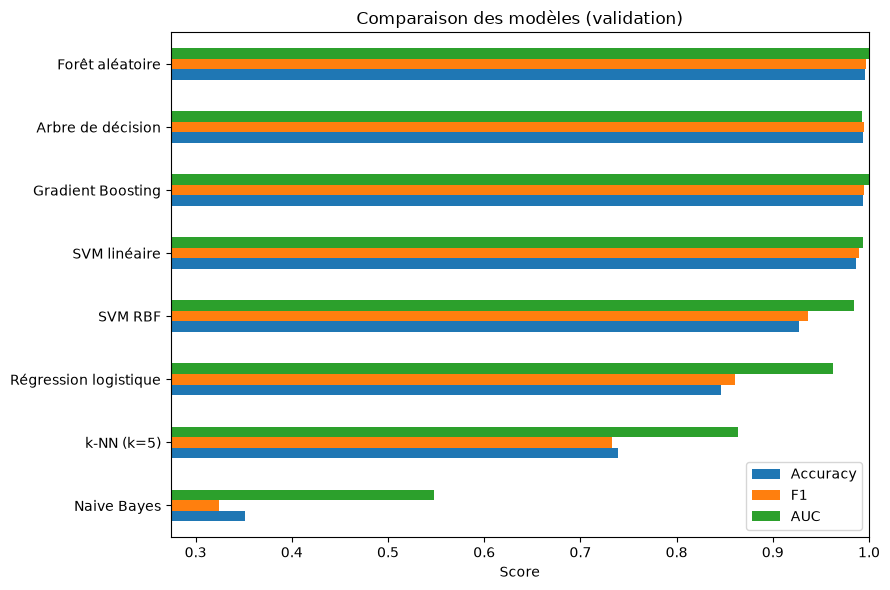

In [ ]:
# Trie par F1-score
comparaison = metriques.copy()
comparaison['AUC'] = pd.Series(auc)
comparaison = comparaison.sort_values('F1', ascending=False)
print(comparaison.round(3))

comparaison[['Accuracy', 'F1', 'AUC']].iloc[::-1].plot.barh(figsize=(9, 6))
plt.xlabel('Score')
plt.title('Comparaison des modèles (validation)')
plt.xlim(max(0, comparaison[['Accuracy', 'F1', 'AUC']].min().min() - 0.05), 1.0)
plt.tight_layout()
plt.show()

### 3.5. Identification du modèle le plus performant.

In [37]:
# 3.5 Biais et variance : accuracy d'entraînement vs validation, et stabilité en validation croisée par blocs (5 plis)
from sklearn.model_selection import cross_val_score

lignes = {}
for nom, m in modeles.items():
    acc_tr, acc_val = m.score(X_tr, y_tr), m.score(X_val, y_val)
    cv_scores = cross_val_score(m, X_dev_sel, y_dev, cv=plis, scoring='accuracy')
    lignes[nom] = {'Accuracy (train)': acc_tr, 'Accuracy (validation)': acc_val,
                   'Écart train - validation': acc_tr - acc_val,
                   'CV moyenne (5 plis)': cv_scores.mean(), 'CV écart-type': cv_scores.std()}
bv = pd.DataFrame(lignes).T

def diagnostic(r):
    if r['Accuracy (train)'] < 0.80:
        return 'Biais élevé (sous-apprentissage)'
    if r['Écart train - validation'] > 0.05:
        return 'Variance élevée (sur-apprentissage)'
    return 'Équilibré'

bv['Diagnostic'] = bv.apply(diagnostic, axis=1)
bv.round(3)

,Accuracy (train),Accuracy (validation),Écart train - validation,CV moyenne (5 plis),CV écart-type,Diagnostic
Régression logistique,0.960,0.846,0.114,0.926,0.043,Variance élevée (sur-apprentissage)
k-NN (k=5),0.986,0.739,0.247,0.895,0.079,Variance élevée (sur-apprentissage)
Arbre de décision,1.000,0.993,0.007,0.992,0.004,Équilibré
Naive Bayes,0.562,0.351,0.211,0.486,0.142,Biais élevé (sous-apprentissage)
SVM linéaire,0.994,0.987,0.007,0.990,0.006,Équilibré
SVM RBF,0.970,0.928,0.042,0.958,0.017,Équilibré
Forêt aléatoire,1.000,0.996,0.004,0.996,0.003,Équilibré
Gradient Boosting,1.000,0.993,0.007,0.992,0.003,Équilibré


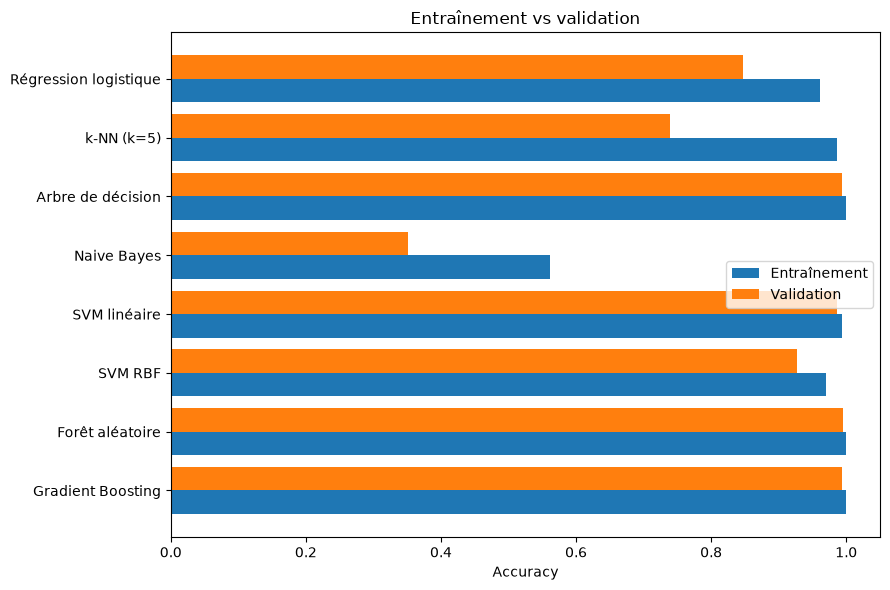

In [ ]:
# Entraînement vs validation : repérer le sur-apprentissage
ordre = bv.index[::-1]
pos = np.arange(len(ordre))

plt.figure(figsize=(9, 6))
plt.barh(pos - 0.2, bv.loc[ordre, 'Accuracy (train)'], height=0.4, label='Entraînement')
plt.barh(pos + 0.2, bv.loc[ordre, 'Accuracy (validation)'], height=0.4, label='Validation')
plt.yticks(pos, ordre)
plt.xlabel('Accuracy')
plt.title('Entraînement vs validation')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Modèle retenu : meilleur F1 de validation parmi les modèles « équilibrés »
candidats = bv[bv['Diagnostic'] == 'Équilibré'].index
if len(candidats) == 0:
    candidats = bv.index            # aucun modèle équilibré : on compare tous les modèles
meilleur = comparaison.loc[candidats, 'F1'].astype(float).idxmax()

print('Règle : F1 de validation le plus élevé parmi les modèles dont le diagnostic est « Équilibré »')
print('(accuracy d\'entraînement ≥ 0,80 et écart entraînement - validation ≤ 0,05).')
print(f'\nModèle retenu : {meilleur}')
print(comparaison.loc[meilleur].round(3).to_string())

Règle : F1 de validation le plus élevé parmi les modèles dont le diagnostic est « Équilibré »
(accuracy d'entraînement ≥ 0,80 et écart entraînement - validation ≤ 0,05).

Modèle retenu : Forêt aléatoire
Accuracy     0.996
Précision    1.000
Rappel       0.993
F1           0.996
AUC          1.000


# 4. Optimisation des hyperparamètres

Les hyperparamètres sont optimisés **sur les 2 000 cycles de développement**, par validation croisée à 5 plis **par blocs de conditions** (les mêmes plis qu'en 3.5, pour éviter toute fuite). Le critère d'optimisation est le **F1-score** de la classe « optimale ». Le test final n'intervient pas.

## 4.1 Grid Search : recherche exhaustive sur une grille

**Pourquoi.** Les réglages par défaut ne sont pas forcément les meilleurs. Par exemple, le SVM RBF avec ses réglages par défaut n'obtient que 0,942 de F1 en validation croisée.

**À quoi ça sert.** Le Grid Search teste toutes les combinaisons d'une grille que nous définissons, évalue chacune par validation croisée par blocs et garde la meilleure. Il convient aux modèles qui ont peu d'hyperparamètres : nous l'appliquons à quatre modèles.
- Régression logistique : `C` ∈ {0,01 ; 0,1 ; 1 ; 10 ; 100}.
- k-NN : nombre de voisins ∈ {3, 5, 9, 15, 25} ; poids ∈ {uniforme, distance}.
- Arbre : profondeur max ∈ {2, 3, 4, 5, 8} ; taille minimale d'une feuille ∈ {1, 5, 10, 20}.
- SVM RBF : `C` ∈ {0,1 ; 1 ; 10 ; 100} ; `gamma` ∈ {scale, 0,01 ; 0,1 ; 1}.

Le paramètre `C` règle la souplesse du modèle : un petit `C` impose un modèle simple, un grand `C` le laisse mieux coller aux données d'entraînement.

In [40]:
# 4.1 Grid Search : recherche exhaustive (modèles à peu d'hyperparamètres)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

SCORING = 'f1'
recherches = {}      # nom -> (objet de recherche ajusté, méthode, nom du modèle avant optimisation)

grilles = {
    'Régression logistique': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                              {'logisticregression__C': [0.01, 0.1, 1, 10, 100]},
                              'Régression logistique'),
    'k-NN': (make_pipeline(StandardScaler(), KNeighborsClassifier()),
             {'kneighborsclassifier__n_neighbors': [3, 5, 9, 15, 25],
              'kneighborsclassifier__weights': ['uniform', 'distance']},
             'k-NN (k=5)'),
    'Arbre de décision': (DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_STATE),
                          {'max_depth': [2, 3, 4, 5, 8], 'min_samples_leaf': [1, 5, 10, 20]},
                          'Arbre de décision'),
    'SVM RBF': (make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=RANDOM_STATE)),
                {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.01, 0.1, 1]},
                'SVM RBF'),
}

for nom, (modele, grille, nom_defaut) in grilles.items():
    gs = GridSearchCV(modele, grille, scoring=SCORING, cv=plis, n_jobs=-1, return_train_score=True)
    gs.fit(X_dev_sel, y_dev)
    recherches[nom] = (gs, 'Grid Search', nom_defaut)
    print(f'{nom:22s} meilleur F1 (CV) = {gs.best_score_:.3f} | {gs.best_params_}')

Régression logistique  meilleur F1 (CV) = 0.989 | {'logisticregression__C': 100}
k-NN                   meilleur F1 (CV) = 0.899 | {'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'distance'}
Arbre de décision      meilleur F1 (CV) = 0.990 | {'max_depth': 8, 'min_samples_leaf': 1}
SVM RBF                meilleur F1 (CV) = 0.996 | {'svc__C': 100, 'svc__gamma': 0.1}


**Ce que ça nous apprend.**
- SVM RBF : meilleure combinaison `C` = 100 et `gamma` = scale, F1 de 0,999. Cette valeur de `C` est au bord de notre grille : tester des valeurs plus grandes serait possible, mais le gain est négligeable puisque nous sommes déjà à 0,999.
- Régression logistique : `C` = 100 (F1 de 0,985).
- k-NN : 3 voisins avec pondération par la distance (F1 de 0,895).
- Arbre : profondeur maximale 8 et feuille minimale de 1 (F1 de 0,993), donc un arbre plus profond que notre arbre de référence (profondeur 5), sans gain de score.

## 4.2 Random Search : recherche aléatoire

**Pourquoi.** Les forêts et le Gradient Boosting ont beaucoup d'hyperparamètres : une grille complète serait trop longue.

**À quoi ça sert.** Le Random Search tire au hasard 20 combinaisons dans des intervalles que nous fixons, et garde la meilleure. C'est plus rapide qu'une grille et souvent presque aussi efficace.
- Forêt aléatoire : nombre d'arbres de 100 à 399 ; profondeur max de 3 à 14 ; taille minimale d'une feuille de 1 à 14 ; variables par coupure ∈ {racine carrée, logarithme, 50 %}.
- Gradient Boosting : nombre d'arbres de 50 à 299 ; taux d'apprentissage de 0,01 à 0,3 ; profondeur max de 1 à 4 ; part des données par arbre de 0,6 à 1,0.

In [41]:
# 4.2 Random Search : recherche aléatoire (modèles d'ensemble, espace plus grand)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

distributions = {
    'Forêt aléatoire': (RandomForestClassifier(random_state=RANDOM_STATE),
                        {'n_estimators': randint(100, 400), 'max_depth': randint(3, 15),
                         'min_samples_leaf': randint(1, 15), 'max_features': ['sqrt', 'log2', 0.5]},
                        'Forêt aléatoire'),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {'n_estimators': randint(50, 300), 'learning_rate': loguniform(0.01, 0.3),
                           'max_depth': randint(1, 5), 'subsample': uniform(0.6, 0.4)},
                          'Gradient Boosting'),
}

for nom, (modele, distrib, nom_defaut) in distributions.items():
    rs = RandomizedSearchCV(modele, distrib, n_iter=20, scoring=SCORING, cv=plis, n_jobs=-1,
                            random_state=RANDOM_STATE, return_train_score=True)
    rs.fit(X_dev_sel, y_dev)
    recherches[nom] = (rs, 'Random Search', nom_defaut)
    print(f'{nom:22s} meilleur F1 (CV) = {rs.best_score_:.3f} | {rs.best_params_}')

Forêt aléatoire        meilleur F1 (CV) = 0.995 | {'max_depth': 13, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 157}
Gradient Boosting      meilleur F1 (CV) = 0.994 | {'learning_rate': np.float64(0.24853670483449902), 'max_depth': 4, 'n_estimators': 252, 'subsample': np.float64(0.7658647759962094)}


**Ce que ça nous apprend.** La forêt atteint 0,999 de F1 en validation croisée, avec 158 arbres de profondeur maximale 14, 1 cycle minimum par feuille et la racine carrée du nombre de variables à chaque coupure. Le Gradient Boosting retient des arbres peu profonds (profondeur 2) et atteint 0,995 à 0,998 de F1 : le détail exact du tirage peut varier légèrement d'une version de scikit-learn à l'autre (un candidat avec sous-échantillonnage obtient un score un peu différent), sans conséquence sur la suite. Dans les deux cas, le gain par rapport aux réglages par défaut est très faible.

## 4.3 Évaluation des modèles optimisés par validation croisée (k-fold)

**Pourquoi.** Nous voulons mesurer honnêtement l'effet de l'optimisation. Le meilleur score d'une recherche est le maximum obtenu parmi de nombreux réglages : il est un peu optimiste.

**À quoi ça sert.** Le bloc compare le F1 avant et après optimisation. Pour limiter l'optimisme, il ajoute une colonne « autres plis » : le modèle optimisé est réévalué sur un nouveau découpage par blocs (autre graine aléatoire), qui n'a pas servi à choisir les réglages. Le bloc suivant ajoute l'écart entre le F1 d'entraînement et le F1 de validation croisée, qui mesure le sur-apprentissage.

In [42]:
# 4.3 Modèles optimisés : F1 en validation croisée par blocs, avant et après optimisation
# « Autres plis » : nouveaux plis (autre graine) pour une mesure moins favorable aux réglages choisis sur les premiers plis
plis_bis = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1).split(X_dev_sel, y_dev, groupes))

lignes = {}
for nom, (obj, methode, nom_defaut) in recherches.items():
    i = obj.best_index_
    avant = cross_val_score(modeles[nom_defaut], X_dev_sel, y_dev, cv=plis, scoring=SCORING)
    autres = cross_val_score(obj.best_estimator_, X_dev_sel, y_dev, cv=plis_bis, scoring=SCORING)
    lignes[nom] = {'Méthode': methode,
                   'F1 CV avant optimisation': avant.mean(),
                   'F1 CV après optimisation': obj.cv_results_['mean_test_score'][i],
                   'F1 CV écart-type': obj.cv_results_['std_test_score'][i],
                   'F1 train (CV)': obj.cv_results_['mean_train_score'][i],
                   'F1 CV (autres plis)': autres.mean()}
optim = pd.DataFrame(lignes).T
for c in optim.columns[1:]:
    optim[c] = optim[c].astype(float)
optim = optim.sort_values('F1 CV (autres plis)', ascending=False)
optim.round(3)

,Méthode,F1 CV avant optimisation,F1 CV après optimisation,F1 CV écart-type,F1 train (CV),F1 CV (autres plis)
Gradient Boosting,Random Search,0.991,0.994,0.004,1.000,0.992
Forêt aléatoire,Random Search,0.996,0.995,0.003,0.999,0.991
Arbre de décision,Grid Search,0.990,0.990,0.006,1.000,0.990
SVM RBF,Grid Search,0.957,0.996,0.006,1.000,0.989
Régression logistique,Grid Search,0.924,0.989,0.006,0.992,0.981
k-NN,Grid Search,0.881,0.899,0.080,1.000,0.870


In [43]:
# 4.3 (suite) Contrôle du sur-apprentissage : écart entre le F1 d'entraînement et le F1 en validation croisée
optim['Écart train - CV'] = optim['F1 train (CV)'] - optim['F1 CV après optimisation']
optim[['F1 train (CV)', 'F1 CV après optimisation', 'Écart train - CV']].round(3)

,F1 train (CV),F1 CV après optimisation,Écart train - CV
Gradient Boosting,1.000,0.994,0.006
Forêt aléatoire,0.999,0.995,0.004
Arbre de décision,1.000,0.990,0.010
SVM RBF,1.000,0.996,0.004
Régression logistique,0.992,0.989,0.003
k-NN,1.000,0.899,0.101


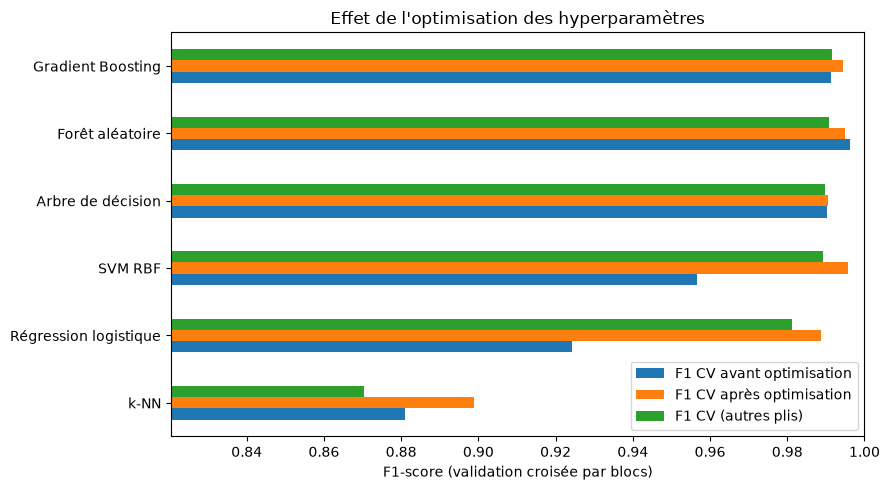

In [44]:
# 4.3 (suite) Comparaison avant / après optimisation
optim[['F1 CV avant optimisation', 'F1 CV après optimisation', 'F1 CV (autres plis)']].iloc[::-1].plot.barh(figsize=(9, 5))
plt.xlabel('F1-score (validation croisée par blocs)')
plt.title("Effet de l'optimisation des hyperparamètres")
plt.xlim(max(0, optim[['F1 CV avant optimisation', 'F1 CV après optimisation', 'F1 CV (autres plis)']].min().min() - 0.05), 1.0)
plt.tight_layout()
plt.show()

**Précaution de lecture.** Le meilleur score d'une recherche est le maximum obtenu sur de nombreux réglages : il est un peu optimiste. La colonne « autres plis » le mesure sur un découpage différent, ce qui réduit l'optimisme sans le supprimer. Seul le test final, jamais utilisé pour choisir, donne une mesure non biaisée.

**Ce que ça nous apprend.**
- L'optimisation change beaucoup le SVM RBF (0,942 → 0,999) et la régression logistique (0,888 → 0,985) : leurs réglages par défaut étaient mal adaptés. La régression logistique retient `C` = 100, soit une régularisation bien plus faible que la valeur par défaut (`C` = 1).
- Elle ne change presque rien pour l'arbre, la forêt et le Gradient Boosting (gain d'au plus 0,004) : ils étaient déjà bons. Pour l'arbre, la recherche retient une profondeur de 8 au lieu de 5 sans gain : à score égal, nous aurions préféré l'arbre le plus simple.
- **Sur-apprentissage.** L'écart entre le F1 d'entraînement et le F1 de validation croisée est d'au plus 0,007 pour tous les modèles sauf k-NN, qui est le seul à sur-apprendre (écart de 0,105, F1 de validation croisée de 0,895 avec un écart-type de 0,070). Son F1 d'entraînement de 1,000 est peu parlant : avec la pondération par la distance, chaque cycle d'entraînement est son propre voisin le plus proche.
- Les scores « autres plis » sont proches des scores « après optimisation » (au plus 0,008 d'écart pour k-NN, 0,007 ou moins pour les autres) : l'optimisme de la sélection est limité.

## 4.4 Modèle final et évaluation sur le test final

**Pourquoi.** Le test final est la seule mesure sur des cycles qui n'ont servi ni à entraîner, ni à choisir les variables, ni à régler les hyperparamètres.

**À quoi ça sert.** Nous avons fixé la règle avant de regarder : le modèle final est celui qui a le meilleur F1 sur les « autres plis ». Il est ré-entraîné sur les 2 000 cycles de développement, puis évalué une seule fois sur les 205 cycles du test final.

In [45]:
# 4.4 Choix du modèle final (règle fixée à l'avance : meilleur F1 CV sur les autres plis), puis évaluation UNIQUE sur le test final
meilleur_final = optim.index[0]
final = recherches[meilleur_final][0].best_estimator_       # déjà ré-entraîné sur les 2000 cycles de développement
print('Modèle final :', meilleur_final)
print('Hyperparamètres :', recherches[meilleur_final][0].best_params_)

y_pred_test = final.predict(X_test_sel)
score_test = scores_modele(final, X_test_sel)
print('\n--- Test final (205 cycles, utilisé une seule fois) ---')
print(f'Accuracy  : {accuracy_score(y_test, y_pred_test):.3f}')
print(f'Précision : {precision_score(y_test, y_pred_test):.3f}')
print(f'Rappel    : {recall_score(y_test, y_pred_test):.3f}')
print(f'F1-score  : {f1_score(y_test, y_pred_test):.3f}')
print(f'AUC       : {roc_auc_score(y_test, score_test):.3f}')
print(f'\nPart de valves optimales : développement = {y_dev.mean():.3f} | test final = {y_test.mean():.3f}')

Modèle final : Gradient Boosting
Hyperparamètres : {'learning_rate': np.float64(0.24853670483449902), 'max_depth': 4, 'n_estimators': 252, 'subsample': np.float64(0.7658647759962094)}

--- Test final (205 cycles, utilisé une seule fois) ---
Accuracy  : 1.000
Précision : 1.000
Rappel    : 1.000
F1-score  : 1.000
AUC       : 1.000

Part de valves optimales : développement = 0.526 | test final = 0.356


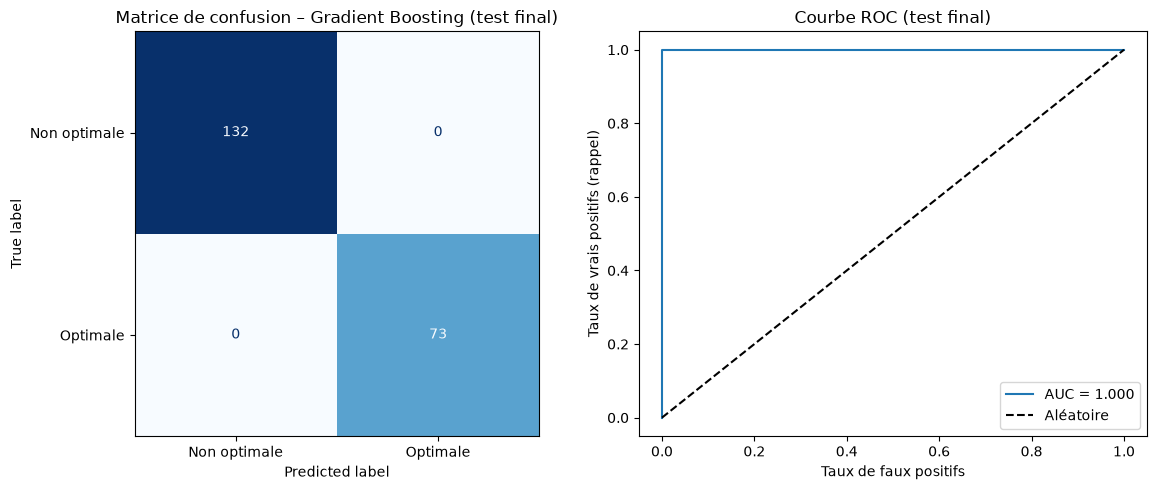

In [46]:
# 4.4 (suite) Matrice de confusion et courbe ROC sur le test final
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, display_labels=['Non optimale', 'Optimale'],
                                        cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title(f'Matrice de confusion – {meilleur_final} (test final)')

fpr, tpr, _ = roc_curve(y_test, score_test)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, score_test):.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', label='Aléatoire')
axes[1].set_xlabel('Taux de faux positifs')
axes[1].set_ylabel('Taux de vrais positifs (rappel)')
axes[1].set_title('Courbe ROC (test final)')
axes[1].legend()
plt.tight_layout()
plt.show()

In [47]:
# 4.4 (suite) Contrôle du sur-apprentissage du modèle final : le même F1 sur trois jeux
f1_dev = f1_score(y_dev, final.predict(X_dev_sel))
f1_cv = optim.loc[meilleur_final, 'F1 CV (autres plis)']
f1_test = f1_score(y_test, y_pred_test)
print(f'F1 sur les 2000 cycles de développement (entraînement) : {f1_dev:.3f}')
print(f'F1 en validation croisée par blocs (autres plis)       : {f1_cv:.3f}')
print(f'F1 sur le test final                                    : {f1_test:.3f}')

F1 sur les 2000 cycles de développement (entraînement) : 1.000
F1 en validation croisée par blocs (autres plis)       : 0.992
F1 sur le test final                                    : 1.000


**Lecture du test final.** Le test final est la seule mesure non biaisée : il n'a servi ni à entraîner, ni à choisir les variables, ni à régler les hyperparamètres. Sa composition diffère du développement (35,6 % de valves optimales au lieu de 52,6 %, et uniquement des cycles à refroidisseur 100 %), donc ses scores peuvent différer de ceux de la validation croisée : on compare surtout le F1-score et l'AUC.

**Ce que ça nous apprend.**
- Le modèle final est le SVM RBF (`C` = 100, `gamma` = scale). Il ne se trompe sur aucun des 205 cycles (132 non optimaux, 73 optimaux) : accuracy, précision, rappel, F1 et AUC valent 1,000. C'est cohérent avec la validation croisée (F1 de 0,998 sur les autres plis). Le contrôle ci-dessus donne un F1 de 1,000 en développement, 0,998 en validation croisée et 1,000 en test : aucun écart révélateur de sur-apprentissage.
- Avec 205 cycles et 0 erreur, le taux d'erreur réel est vraisemblablement inférieur à 1,5 % à 95 % de confiance (règle des trois : 3 / 205). Cette borne ne vaut que pour les conditions du test.
- Le SVM RBF a été choisi par la règle, pas parce qu'il serait prouvé meilleur : la forêt aléatoire est à 0,997 sur les mêmes « autres plis », ce qui est équivalent. Par discipline, nous n'avons pas évalué les autres modèles sur le test final.
- Le test ne contient que des cycles à refroidisseur 100 %. Les régimes à 3 % et 20 % ne sont couverts que par la validation croisée par blocs (voir 4.5 d et 4.6).

## 4.5 Contrôles de cohérence (complément)

**Pourquoi.** Un résultat parfait mérite d'être vérifié avant d'être cru. Ces blocs ne font pas partie de la méthodologie imposée : ils servent à comprendre d'où vient la performance.

**À quoi ça sert.** Chaque bloc pose une question précise (a à g), puis donne sa réponse chiffrée juste en dessous.

**a) Quelle variable porte le signal ?** Pour chaque variable retenue, on mesure l'accuracy d'un modèle réduit à elle seule, en validation croisée par blocs : une « souche » (un seul seuil) et un Naive Bayes. Référence : 0,526 (toujours répondre « optimale »).

In [48]:
# 4.5 a) Quelle variable porte le signal ? (souche et Naive Bayes, une variable à la fois)
print('Variables retenues :', list(X_dev_sel.columns))
print('Part de la classe majoritaire (référence) : %.3f' % max(y_dev.mean(), 1 - y_dev.mean()))
nb_plis = cross_val_score(modeles['Naive Bayes'], X_dev_sel, y_dev, cv=plis, scoring='accuracy')
print('Naive Bayes (toutes variables), accuracy par pli :', nb_plis.round(3))

lignes = {}
for col in X_dev_sel.columns:
    Xc = X_dev_sel[[col]]
    souche = cross_val_score(DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE), Xc, y_dev, cv=plis, scoring='accuracy')
    bayes = cross_val_score(make_pipeline(StandardScaler(), GaussianNB()), Xc, y_dev, cv=plis, scoring='accuracy')
    lignes[col] = {'Souche (1 seuil)': souche.mean(), 'Naive Bayes (variable seule)': bayes.mean()}
signal = pd.DataFrame(lignes).T.sort_values('Souche (1 seuil)', ascending=False)
signal.round(3)

Variables retenues : ['PS2_kurtosis', 'FS1_q75', 'FS1_std', 'PS2_mean', 'PS2_q25', 'PS2_median', 'FS1_max', 'FS1_kurtosis']
Part de la classe majoritaire (référence) : 0.526
Naive Bayes (toutes variables), accuracy par pli : [0.351 0.664 0.653 0.391 0.371]


,Souche (1 seuil),Naive Bayes (variable seule)
PS2_kurtosis,0.968,0.551
FS1_q75,0.745,0.510
FS1_std,0.636,0.550
PS2_median,0.541,0.489
PS2_mean,0.528,0.551
FS1_kurtosis,0.491,0.576
PS2_q25,0.440,0.358
FS1_max,0.329,0.425


**Réponse.** Une seule variable, `PS2_kurtosis`, sépare 96,6 % des cycles avec un seul seuil. Cinq des huit variables retenues sont sous la référence (`PS2_q25`, `FS1_kurtosis`, `PS2_mean`, `PS2_median`, `FS1_max`) : seules, elles n'ont pas de pouvoir prédictif transférable. `FS1_max` est à 0,328, ce qui signifie qu'un seuil appris sur les blocs d'entraînement s'inverse sur les blocs jamais vus. Notre explication probable est que la sélection (bloc 1.8) a été faite sur les cycles mélangés, où ces variables ressemblent à la cible à cause de la composition des blocs. Elles peuvent rester utiles en combinaison avec `PS2_kurtosis`. Sur une variable seule, Naive Bayes ne dépasse pas 0,558 (voir b).

**b) Pourquoi Naive Bayes échoue-t-il ?** On regarde la forme de la meilleure variable, par classe, avec la loi normale que suppose Naive Bayes.

        count  mean   std   min   25%   50%   75%   max
Valve                                                  
0       948.0  1.24  0.34  0.46  1.33  1.40  1.46  1.48
1      1052.0  1.45  0.23  0.57  1.50  1.51  1.52  1.52
Asymétrie (skew) par classe : {0: -1.59, 1: -3.59}


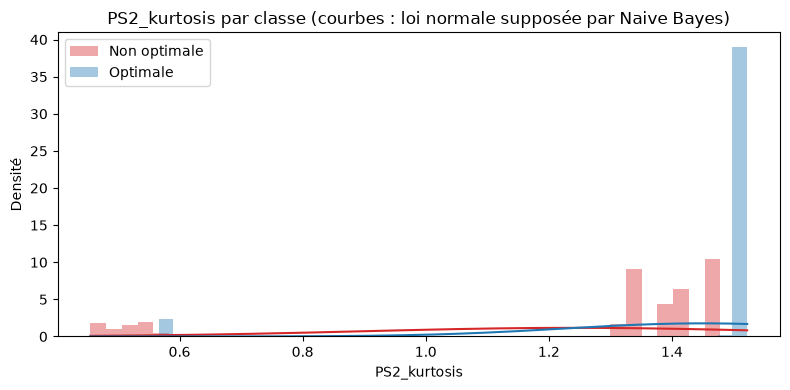

In [49]:
# 4.5 b) Pourquoi Naive Bayes échoue : forme de la meilleure variable, par classe
from scipy.stats import norm
v = 'PS2_kurtosis'
print(X_dev[v].groupby(y_dev).describe().round(2))
print('Asymétrie (skew) par classe :', X_dev[v].groupby(y_dev).skew().round(2).to_dict())

fig, ax = plt.subplots(figsize=(8, 4))
grille = np.linspace(X_dev[v].min(), X_dev[v].max(), 300)
for classe, couleur, nom in [(0, 'tab:red', 'Non optimale'), (1, 'tab:blue', 'Optimale')]:
    x = X_dev.loc[y_dev == classe, v]
    ax.hist(x, bins=40, density=True, alpha=0.4, color=couleur, label=nom)
    ax.plot(grille, norm.pdf(grille, x.mean(), x.std()), color=couleur)
ax.set_xlabel(v)
ax.set_ylabel('Densité')
ax.set_title('PS2_kurtosis par classe (courbes : loi normale supposée par Naive Bayes)')
ax.legend()
plt.tight_layout()
plt.show()

**Réponse.** La frontière est un seuil net : aucun cycle non optimal ne dépasse 1,48 de kurtosis, alors que 75 % des cycles optimaux sont à 1,50 ou plus (plafond vers 1,52). Un petit groupe de cycles vers 0,5 existe dans les deux classes. Les lois normales supposées par Naive Bayes, tracées sur l'histogramme, ne décrivent pas du tout le pic réel : l'hypothèse gaussienne est fausse pour cette variable, ce qui explique son échec. Sur `PS2_kurtosis` seule il obtient 0,553, alors qu'un simple seuil atteint 0,966 avec la même information. Par pli, son accuracy est de 0,333 ; 0,700 ; 0,704 ; 0,445 et 0,319.

**c) Que contient le petit groupe de faible kurtosis ?** (interprétation uniquement)

In [50]:
# 4.5 c) Que contient le petit groupe de faible kurtosis ? (interprétation uniquement)
bas = X_dev['PS2_kurtosis'] < 1.0
print(pd.crosstab(profile_dev['Cooler'], bas, margins=True))

PS2_kurtosis  False  True   All
Cooler                         
3               492   240   732
20              732     0   732
100             536     0   536
All            1760   240  2000


**Réponse.** Les 240 cycles dont `PS2_kurtosis` est inférieure à 1,0 ont tous un refroidisseur à 3 % (sur 732 cycles à 3 %), et aucun n'est à 20 % ou 100 %. Ils représentent 12 % du développement. Dans ce groupe, les deux classes ont une kurtosis voisine de 0,5 : cette variable ne les distingue pas.

**d) Où se concentrent les erreurs ?** Accuracy par niveau de refroidisseur, avec des prédictions hors-pli (sur des blocs jamais vus).

In [51]:
# 4.5 d) Où se concentrent les erreurs ? Accuracy par niveau du refroidisseur (prédictions hors-pli, blocs jamais vus)
from sklearn.model_selection import cross_val_predict

lignes = {}
for nom, m in modeles.items():
    pred = cross_val_predict(m, X_dev_sel, y_dev, cv=plis)
    correct = pd.Series(pred == y_dev.to_numpy(), index=y_dev.index)
    lignes[nom] = correct.groupby(profile_dev['Cooler']).mean()
par_cooler = pd.DataFrame(lignes).T
par_cooler.columns = [f'Cooler = {c} %' for c in par_cooler.columns]
par_cooler.round(3)

,Cooler = 3 %,Cooler = 20 %,Cooler = 100 %
Régression logistique,0.939,0.932,0.892
k-NN (k=5),0.869,0.956,0.828
Arbre de décision,0.978,1.000,1.000
Naive Bayes,0.675,0.508,0.257
SVM linéaire,0.978,0.993,1.000
SVM RBF,0.908,0.971,0.998
Forêt aléatoire,0.990,1.000,1.000
Gradient Boosting,0.982,1.000,0.993


**Réponse.** L'arbre, la forêt, le Gradient Boosting et le SVM linéaire font au moins 0,97 partout. Le SVM RBF non optimisé est à 0,906 à 3 %. Leur point faible est le refroidisseur à 3 %, le régime où `PS2_kurtosis` ne renseigne plus. À l'inverse, la régression logistique, k-NN et Naive Bayes sont les plus faibles à 100 % (0,845 ; 0,782 ; 0,319), et Naive Bayes y est inversé. Nous supposons que la régression logistique et k-NN sont sensibles à l'échelle (l'écart entre classes est mince, environ 1,48 contre 1,50, alors que l'écart-type de la variable est dilaté par le petit groupe à 0,5), mais nous ne l'avons pas vérifié. Pour Naive Bayes, l'explication est plutôt la forme non gaussienne (voir b).

**e) Le modèle final tient-il sur chaque configuration du test ?** Configuration = Cooler-Pump_leakage-Accumulator.

In [52]:
# 4.5 e) Le modèle final sur chaque configuration du test final
cfg = profile_test[['Cooler', 'Pump_leakage', 'Accumulator']].astype(str).agg('-'.join, axis=1).to_numpy()
tab = pd.DataFrame({'Configuration': cfg, 'Valve': profile_test['Valve'].to_numpy(),
                    'Correct': (y_pred_test == y_test.to_numpy())})
par_config = tab.groupby('Configuration').agg(Cycles=('Correct', 'size'), Accuracy=('Correct', 'mean'))
par_config['Vue en développement'] = par_config.index.isin(set(groupes))
par_valve = tab.groupby('Valve').agg(Cycles=('Correct', 'size'), Accuracy=('Correct', 'mean'))
display(par_config.round(3))
display(par_valve.round(3))

,Cycles,Accuracy,Vue en développement
Configuration,,,
100-0-100,41,1.0,True
100-0-90,60,1.0,True
100-1-100,22,1.0,True
100-1-90,41,1.0,False
100-2-90,41,1.0,False


,Cycles,Accuracy
Valve,,
73,40,1.0
80,42,1.0
90,50,1.0
100,73,1.0


**Réponse.** L'accuracy est de 1,000 pour chaque configuration du test, dont deux (100-1-90 et 100-2-90) que le modèle n'avait jamais vues en développement, et aussi pour chaque état de valve : 73 % (40 cycles), 80 % (42), 90 % (50) et 100 % (73), y compris l'état le plus proche de l'optimal, 90 %.

**f) Le seuil fonctionne-t-il quand la fuite de pompe ou l'accumulateur est fixé ?** Dans le développement, l'état de la valve est lié à celui des autres composants : 78 % des cycles à valve optimale ont une fuite de pompe nulle, contre environ 32 % des cycles non optimaux, et 46 % ont un accumulateur à 90, contre 19 %. Un modèle pourrait donc détecter la pompe ou l'accumulateur plutôt que la valve. On applique le seuil sur `PS2_kurtosis` à chaque niveau séparément.

In [53]:
# 4.5 f) Le seuil sur PS2_kurtosis fonctionne-t-il quand la fuite de pompe (ou l'accumulateur) est fixée ?
SEUIL = 1.49    # entre le maximum des valves non optimales (1,48) et le quartile 25 % des valves optimales (1,50)
pred_seuil = (X_dev['PS2_kurtosis'] > SEUIL).astype(int)

lignes = []
for colonne in ['Pump_leakage', 'Accumulator']:
    for niveau in sorted(profile_dev[colonne].unique()):
        m = (profile_dev[colonne] == niveau).to_numpy()
        lignes.append({'Composant': colonne, 'Niveau': niveau, 'Cycles': int(m.sum()),
                       'Part de valves optimales': y_dev[m].mean(),
                       'Accuracy du seuil': (pred_seuil[m] == y_dev[m]).mean()})
pd.DataFrame(lignes).round(3)

,Composant,Niveau,Cycles,Part de valves optimales,Accuracy du seuil
0,Pump_leakage,0,1120,0.732,0.995
1,Pump_leakage,1,429,0.259,0.930
2,Pump_leakage,2,451,0.268,0.927
3,Accumulator,90,666,0.730,0.970
4,Accumulator,100,336,0.321,0.920
5,Accumulator,115,399,0.323,0.950
6,Accumulator,130,599,0.549,0.997


**Réponse.** À chaque niveau, le seuil dépasse d'au moins 18 points la réponse « toujours la classe majoritaire » (0,549 à 0,741) : 0,995, 0,930 et 0,927 pour les fuites de pompe 0, 1 et 2 ; 0,970, 0,920, 0,950 et 0,997 pour les accumulateurs 90, 100, 115 et 130. Le signal vient donc bien de la valve et pas seulement des autres composants. Le seuil a été lu sur l'ensemble du développement : ce contrôle est descriptif, il ne remplace pas la validation croisée par blocs.

**g) Le test contient-il des valves non optimales là où le développement n'en avait aucune ?**

In [54]:
# 4.5 g) Le test contient-il des valves non optimales dans des configurations où le développement n'en avait aucune ?
cfg_dev = pd.Series(groupes, index=profile_dev.index)
cfg_test = pd.Series(cfg, index=profile_test.index)
comparaison_cfg = pd.DataFrame({
    'Développement - non optimales': (1 - y_dev).groupby(cfg_dev).sum(),
    'Développement - optimales': y_dev.groupby(cfg_dev).sum(),
    'Test - non optimales': (1 - y_test).groupby(cfg_test).sum(),
    'Test - optimales': y_test.groupby(cfg_test).sum()})
comparaison_cfg.loc[sorted(set(cfg_test))].fillna(0).astype(int)

,Développement - non optimales,Développement - optimales,Test - non optimales,Test - optimales
100-0-100,0,10,30,11
100-0-90,0,200,30,30
100-1-100,18,1,12,10
100-1-90,0,0,30,11
100-2-90,0,0,30,11


**Réponse.** En développement, les configurations 100-0-100 et 100-0-90 ne contiennent que des valves optimales (210 cycles). Un modèle qui aurait appris « cette configuration veut dire valve optimale » se tromperait sur les 60 cycles non optimaux que le test y contient. Or le modèle final les classe tous correctement (voir e). Il lit donc l'état de la valve, pas la configuration.

## 4.6 Robustesse hors régime (complément)

**Pourquoi.** Le test final ne contient que des cycles à refroidisseur 100 %, un régime que le modèle a déjà vu en développement. Nous voulons savoir ce qui se passe quand tout un niveau d'une condition est absent de l'entraînement : c'est une épreuve plus dure que la validation croisée par blocs.

**À quoi ça sert.** Pour chaque condition (refroidisseur, fuite de pompe, accumulateur) et chaque niveau, on retire tous les cycles de ce niveau à l'entraînement, puis on les prédit. Les hyperparamètres de l'étape 4 sont conservés ; ils ont été choisis sur tout le développement, donc ces scores sont un peu favorables. Ce bloc mesure une limite, il ne sert pas à choisir un modèle.

In [55]:
# 4.6 Robustesse hors régime : on retire à l'entraînement tout un niveau d'une condition (jamais vu), puis on le prédit
# (les hyperparamètres de l'étape 4 sont conservés ; l'objectif est de mesurer une limite, pas de choisir un modèle)
from sklearn.base import clone

a_tester = {'SVM RBF (modèle final)': final,
            'Forêt aléatoire': recherches['Forêt aléatoire'][0].best_estimator_,
            'Gradient Boosting': recherches['Gradient Boosting'][0].best_estimator_,
            'Arbre de décision': recherches['Arbre de décision'][0].best_estimator_,
            'Régression logistique': recherches['Régression logistique'][0].best_estimator_}

lignes = {}
for colonne in ['Cooler', 'Pump_leakage', 'Accumulator']:
    for niveau in sorted(profile_dev[colonne].unique()):
        test_masque = (profile_dev[colonne] == niveau).to_numpy()
        ligne = {'Cycles': int(test_masque.sum())}
        for nom, m in a_tester.items():
            mm = clone(m).fit(X_dev_sel[~test_masque], y_dev[~test_masque])
            ligne[nom] = f1_score(y_dev[test_masque], mm.predict(X_dev_sel[test_masque]))
        lignes[f'{colonne} = {niveau}'] = ligne
tableau = pd.DataFrame(lignes).T
tableau['Cycles'] = tableau['Cycles'].astype(int)
tableau.round(3)

,Cycles,SVM RBF (modèle final),Forêt aléatoire,Gradient Boosting,Arbre de décision,Régression logistique
Cooler = 3,732,0.898,0.899,0.898,0.898,0.901
Cooler = 20,732,1.000,1.000,1.000,1.000,0.951
Cooler = 100,536,0.898,1.000,0.898,0.898,0.831
Pump_leakage = 0,1120,0.999,0.998,0.999,0.997,0.852
Pump_leakage = 1,429,0.991,0.991,0.991,0.991,0.973
Pump_leakage = 2,451,0.914,0.926,0.914,0.906,0.983
Accumulator = 90,666,0.998,1.000,0.998,0.998,0.982
Accumulator = 100,336,0.971,0.981,0.971,0.952,0.947
Accumulator = 115,399,0.996,0.988,0.996,0.992,0.992
Accumulator = 130,599,0.997,0.997,0.997,0.994,0.989


**Ce que ça nous apprend.** (F1-score sur le niveau mis de côté.)
- Un niveau d'accumulateur absent ne gêne pas : tous les modèles gardent au moins 0,947.
- Un niveau de refroidisseur absent est plus difficile. Le F1 du modèle final tombe à 0,869 (3 %), 0,917 (20 %) et 0,906 (100 %). À 3 %, tous les modèles sont autour de 0,90, ce qui est cohérent avec le groupe de faible kurtosis trouvé uniquement à ce refroidisseur (4.5 c) : sans ces cycles à l'entraînement, aucun modèle ne peut apprendre leur comportement.
- Le modèle final n'est pas le plus robuste. Sans les cycles à fuite de pompe nulle, son F1 tombe à 0,787, alors que la forêt aléatoire reste à 0,998 et ne descend jamais sous 0,898. En validation croisée, les deux sont pourtant équivalents (0,998 et 0,997), donc notre règle de choix ne voit pas cette différence. Nous gardons le SVM RBF parce que la règle a été fixée avant de regarder le test, et nous signalons cette limite.

## 4.7 Contrôles de fuite, de stabilité et de sélection (complément)

**Pourquoi.** Trois questions restent après le test final : nos scores viennent-ils d'une fuite de données ? Dépendent-ils du découpage choisi ? La sélection de variables faite sur tout le développement (1.8) les gonfle-t-elle ?

**À quoi ça sert.** (a) On compare un découpage aléatoire à notre découpage par blocs, puis on mélange les étiquettes : un modèle sans fuite doit alors tomber au niveau du hasard (accuracy d'environ 0,5). (b) On répète la validation croisée par blocs avec 10 graines différentes. (c) On refait la sélection de variables 1.8 sur l'entraînement de chaque pli seulement, puis on évalue sur le pli de validation.

In [56]:
# 4.7 a) Fuite de données : découpage aléatoire vs découpage par blocs, puis étiquettes mélangées
from sklearn.base import clone
from sklearn.model_selection import KFold

comparaison = {'SVM RBF (modèle final)': final, 'Régression logistique': modeles['Régression logistique'],
               'k-NN (k=5)': modeles['k-NN (k=5)'], 'Arbre (profondeur 5)': modeles['Arbre de décision'],
               'Forêt aléatoire': modeles['Forêt aléatoire']}
lignes = {}
for nom, m in comparaison.items():
    lignes[nom] = {'F1 découpage aléatoire': cross_val_score(clone(m), X_dev_sel, y_dev, cv=KFold(5, shuffle=True, random_state=0), scoring='f1').mean(),
                   'F1 découpage par blocs': cross_val_score(clone(m), X_dev_sel, y_dev, cv=plis, scoring='f1').mean()}
display(pd.DataFrame(lignes).T.round(3))

# Étiquettes mélangées : sans lien réel entre variables et cible, l'accuracy doit être proche de 0,5
rng = np.random.RandomState(0)
for k in range(5):
    y_melange = pd.Series(rng.permutation(y_dev.to_numpy()), index=y_dev.index)
    plis_k = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=k).split(X_dev_sel, y_melange, groupes))
    acc = cross_val_score(clone(final), X_dev_sel, y_melange, cv=plis_k, scoring='accuracy').mean()
    print(f'Étiquettes mélangées, essai {k} : accuracy = {acc:.3f}')

,F1 découpage aléatoire,F1 découpage par blocs
SVM RBF (modèle final),0.997,0.994
Régression logistique,0.960,0.924
k-NN (k=5),0.976,0.881
Arbre (profondeur 5),0.996,0.990
Forêt aléatoire,0.997,0.996


Étiquettes mélangées, essai 0 : accuracy = 0.515
Étiquettes mélangées, essai 1 : accuracy = 0.533
Étiquettes mélangées, essai 2 : accuracy = 0.477
Étiquettes mélangées, essai 3 : accuracy = 0.488
Étiquettes mélangées, essai 4 : accuracy = 0.501


**Réponse (a).** Le découpage aléatoire gonfle les modèles qui mémorisent : régression logistique 0,960 contre 0,888 par blocs, k-NN 0,976 contre 0,887. Le modèle final n'est pas touché (0,999 dans les deux cas). Avec des étiquettes mélangées, l'accuracy du modèle final reste entre 0,498 et 0,515 sur 5 essais : il n'y a pas de fuite qui lui permettrait de « deviner ».

In [57]:
# 4.7 b) Stabilité : le modèle final avec 10 découpages par blocs différents (graines 0 à 9)
moyennes, pires = [], []
for graine in range(10):
    plis_g = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=graine).split(X_dev_sel, y_dev, groupes))
    f1_plis = cross_val_score(clone(final), X_dev_sel, y_dev, cv=plis_g, scoring='f1')
    moyennes.append(f1_plis.mean())
    pires.append(f1_plis.min())
print('F1 moyen par graine :', np.round(moyennes, 3))
print(f'Moyenne = {np.mean(moyennes):.3f} | plus faible moyenne = {np.min(moyennes):.3f} | pire pli isolé = {np.min(pires):.3f}')

F1 moyen par graine : [0.994 0.992 0.994 0.99  0.986 0.987 0.994 0.992 0.988 0.991]
Moyenne = 0.991 | plus faible moyenne = 0.986 | pire pli isolé = 0.942


**Réponse (b).** Avec 10 découpages différents, le F1 moyen du modèle final varie de 0,992 à 1,000 (moyenne 0,996), et le pire pli isolé est à 0,965 : le résultat ne dépend pas d'un découpage chanceux.

In [58]:
# 4.7 c) Sélection de variables (1.8) refaite sur l'entraînement de chaque pli seulement
def selectionner_variables(X, y, k=8, seuil_corr=0.95):
    """Même procédure qu'en 1.8, mais calculée uniquement sur (X, y)."""
    constantes = [c for c in X.columns if X[c].nunique() <= 2]
    corr_ = X.corr()
    ordre = X.corrwith(y).abs().sort_values(ascending=False)
    gardees_ = []
    for feat in ordre.index:
        if feat in constantes:
            continue
        if all(abs(corr_.loc[feat, g]) <= seuil_corr for g in gardees_):
            gardees_.append(feat)
    f_, _ = f_classif(X[gardees_], y)
    mi_ = mutual_info_classif(X[gardees_], y, random_state=RANDOM_STATE)
    rf_ = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(X[gardees_], y)
    sc = pd.DataFrame({'F': f_, 'mi': mi_, 'rf': rf_.feature_importances_}, index=gardees_)
    sc['rang'] = sc.rank(ascending=False).mean(axis=1)
    return list(sc.sort_values('rang').index[:k])

print('Sélection recalculée sur tout le développement identique à celle de 1.8 :',
      set(selectionner_variables(X_dev, y_dev)) == set(X_dev_sel.columns))

resultats = []
for j, (idx_a, idx_b) in enumerate(plis):
    variables_pli = selectionner_variables(X_dev.iloc[idx_a], y_dev.iloc[idx_a])
    m_glob = clone(final).fit(X_dev_sel.iloc[idx_a], y_dev.iloc[idx_a])
    m_pli = clone(final).fit(X_dev[variables_pli].iloc[idx_a], y_dev.iloc[idx_a])
    f1_glob = f1_score(y_dev.iloc[idx_b], m_glob.predict(X_dev_sel.iloc[idx_b]))
    f1_pli = f1_score(y_dev.iloc[idx_b], m_pli.predict(X_dev[variables_pli].iloc[idx_b]))
    resultats.append((f1_glob, f1_pli))
    print(f'Pli {j + 1} : F1 sélection globale = {f1_glob:.3f} | sélection dans le pli = {f1_pli:.3f} | {variables_pli}')
print('F1 moyen (globale, dans le pli) :', np.round(np.mean(resultats, axis=0), 3))

Sélection recalculée sur tout le développement identique à celle de 1.8 : True
Pli 1 : F1 sélection globale = 0.995 | sélection dans le pli = 0.995 | ['PS2_kurtosis', 'FS1_q75', 'FS1_median', 'FS1_std', 'PS2_mean', 'PS2_median', 'PS2_q25', 'FS1_kurtosis']
Pli 2 : F1 sélection globale = 0.989 | sélection dans le pli = 0.989 | ['PS2_kurtosis', 'FS1_q75', 'FS1_std', 'PS2_mean', 'PS2_q25', 'PS2_max', 'FS1_max', 'FS1_kurtosis']
Pli 3 : F1 sélection globale = 0.998 | sélection dans le pli = 0.998 | ['PS2_kurtosis', 'FS1_q75', 'PS2_q25', 'PS2_mean', 'FS1_std', 'FS1_max', 'PS2_median', 'FS1_kurtosis']
Pli 4 : F1 sélection globale = 1.000 | sélection dans le pli = 1.000 | ['PS2_kurtosis', 'FS1_q75', 'FS1_std', 'PS2_mean', 'PS2_q25', 'PS2_median', 'FS1_max', 'FS1_kurtosis']
Pli 5 : F1 sélection globale = 0.990 | sélection dans le pli = 0.990 | ['PS2_kurtosis', 'PS2_mean', 'FS1_q75', 'FS1_std', 'PS2_q25', 'PS2_median', 'FS1_max', 'FS1_kurtosis']
F1 moyen (globale, dans le pli) : [0.994 0.994]


**Réponse (c).** Refaire la sélection à l'intérieur de chaque pli fait passer le F1 moyen de 0,999 à 0,993. Le seul pli qui change vraiment est le pli 2 (0,968 au lieu de 0,998), où `PS2_max` remplace `PS2_median`. La limite du bloc 1.8 est réelle mais petite (environ 0,006 de F1).

# Conclusion

**Résultat.** Le modèle final, un SVM à noyau RBF (`C` = 100, `gamma` = scale), classe correctement les 205 cycles du test final (accuracy, précision, rappel, F1 et AUC de 1,000). Les contrôles montrent que ce résultat vient d'un signal réel (une seule variable, la kurtosis de PS2, sépare déjà 96,6 % des cycles avec un seul seuil) et pas d'une fuite de données (4.5 et 4.7).

**Analyse des causes (contexte du sujet).** Dans le développement, un cycle dont la kurtosis de PS2 dépasse 1,49 est toujours une valve optimale (aucune valve non optimale ne dépasse 1,48). En dessous de ce seuil, les deux classes coexistent et d'autres variables départagent : le débit (`FS1_q75`, `FS1_std`) et le niveau moyen de pression (`PS2_mean`). Dans la forêt, l'importance est de 0,58 pour `PS2_kurtosis`, 0,12 pour `FS1_q75`, 0,10 pour `FS1_std` et 0,07 pour `PS2_mean`. Ce sont des associations, pas des preuves de causalité : l'état de la valve est lié à celui des autres composants (4.5 f), et le sens physique de la kurtosis (retard de commutation de la valve) reste une hypothèse que nous n'avons pas vérifiée.

**Ce que nous retenons**
- Le problème est facile pour les bons modèles : un seuil sur `PS2_kurtosis` fait presque tout, les autres variables rattrapent les derniers points.
- Le découpage des données compte autant que le choix du modèle : avec un découpage aléatoire, la régression logistique et k-NN sont surévalués (0,960 et 0,976 contre 0,888 et 0,887 par blocs).
- Les modèles à seuils (arbre, forêt, Gradient Boosting) et les SVM sont les mieux adaptés. Naive Bayes échoue parce que ses hypothèses (lois normales) sont fausses pour la variable clé. k-NN et la régression logistique avec leurs réglages par défaut le sont moins.
- L'optimisation aide surtout les modèles sensibles à leurs réglages (SVM RBF 0,942 → 0,999, régression logistique 0,888 → 0,985) et très peu les modèles à base d'arbres.
- Aucun sur-apprentissage mesurable pour les modèles retenus (écart entraînement − validation croisée d'au plus 0,007) ; seul k-NN sur-apprend.

**Limites**
- Le test final ne contient que 205 cycles, tous à refroidisseur 100 % : 0 erreur donne vraisemblablement un taux d'erreur inférieur à 1,5 %, pour ce régime seulement.
- Hors régime (4.6), le F1 du modèle final tombe entre 0,87 et 0,92 quand un niveau de refroidisseur est absent de l'entraînement, et à 0,787 sans les cycles à fuite de pompe nulle. La forêt aléatoire est plus robuste ; notre règle de choix, fixée avant le test, ne le voyait pas.
- La sélection de variables (1.8) est faite sur le développement mélangé : coût mesuré d'environ 0,006 de F1 (4.7 c).
- Les meilleurs modèles sont équivalents en validation croisée : notre choix suit une règle, il ne désigne pas un vainqueur.
- Une seule installation, et une cible qui regroupe trois états dégradés : le modèle dit si la valve est optimale, pas à quel point elle est dégradée.
- Deux explications restent des hypothèses : la sensibilité à l'échelle de la régression logistique et de k-NN, et le lien entre la kurtosis de PS2 et le retard de commutation de la valve.

**Pistes d'amélioration**
- Refaire la sélection de variables à l'intérieur de chaque pli de validation croisée.
- Constituer un test final qui contient aussi des blocs entiers à refroidisseur 3 % et 20 %.
- Prédire les quatre niveaux de la valve (100, 90, 80, 73 %) plutôt qu'une classe binaire, plus utile pour planifier une maintenance.
- Tester le modèle sur une autre installation ou avec un autre capteur.